# Classical sticker and face detection

Image processing without learning, on frontal photos of one face. Every method is one figure:
rows are sample photos, columns are its stages, numbered as in the description above the
figure. Runs locally after `dvc pull`.

| ID | Part | Input | Output | Idea |
|---|---|---|---|---|
| K | shared | contour | accepted or not | shape filter: is the region a sticker |
| S1 | A, stickers | photo | sticker contours | ICCVG06: pixel colors, regions, filter K |
| S2 | A, stickers | photo | sticker contours | Canny edges (seams), enclosed regions, K |
| S3 | A, stickers | photo | sticker contours | MSER on the gradient, filter K |
| G | A, stickers | contours of S1, S2 or S3 | 9 stickers | complete the 3 x 3 grid |
| F1 | B, face | photo | quadrilateral | saturation mask |
| F2 | B, face | photo | quadrilateral | outer contour of the Canny edges |
| F3 | B, face | 9 stickers of S2 + G | quadrilateral | corners of the grid |
| R | B, face | quadrilateral | 9 stickers, check | homography, 3 x 3 cells, seam check |

## Parameters

- **Split by cube** (`split_cubes`, sizes and seed of `params.yaml`, the same as for YOLO):
  train, and test = val + test of `params.yaml` (no model is trained, so no validation set).
- **Grids** – every parameter of a method is a grid; the values are derived from
  measurements of the training photos (section *Measurements*) where a measurement applies,
  from their 95th and 99th percentiles rather than the extremes (a few measurements fail).
  `tune` warns when the best value of a numeric grid of 3 or more values is at its edge: the
  optimum may lie beyond; such grids were widened after the first run.
- **Tuning** – every combination is scored on the training photos, the best one is used in
  the figures and evaluated on both sets in the *Summary*. Methods are tuned in order: an S
  method with its own filter K, then G on top of the tuned S, F, then R on top of the tuned F.
- **Criteria:**
  - S1, S2, S3: F1 of stickers; precision = found stickers / returned regions, recall = found
    stickers / 9, both summed over the photos
  - G: photos with all 9 stickers found
  - F1, F2: photos with face IoU >= `FACE_IOU`
  - R: photos accepted by the check with all 9 stickers found minus photos accepted without
    (a false accept cancels a right one), per photo
- Fixed beforehand, not tuned: `WIDTH`, `MIN_IOU`, `FACE_IOU`, `GRID_SIZE`.

## Setup

Panels in the figures are cropped around the annotated face for display only; the methods
see the whole photo.

In [32]:
import functools
import itertools
import platform
import time

import cv2
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import yaml

from puzzle_vision.config import CVAT_ANNOTATIONS, PROJ_ROOT, RAW_IMAGES_DIR
from puzzle_vision.cube import COLOR
from puzzle_vision.dataset import annotated_images
from puzzle_vision.split import split_cubes

In [33]:
%config InlineBackend.figure_formats = ["jpeg"]
FIGURES = {"bbox_inches": "tight", "dpi": 60, "pil_kwargs": {"quality": 70}}  # notebook size
%config InlineBackend.print_figure_kwargs = FIGURES

WIDTH = 750  # px, photos are downscaled from 3000; pixel parameters are at this size
MIN_IOU = 0.5  # a region is an annotated sticker if their IoU is at least this
FACE_IOU = 0.9  # a quadrilateral is the face if its IoU with the annotated face is at least this
GRID_SIZE = 300  # px, side of a rectified face
SAMPLES = [  # cube, photo file prefix
    ("cube_0001", "1"),  # fabric
    ("cube_0004", "3"),  # wood
    ("cube_0009", "5"),  # gray desk
    ("cube_0011", "1"),  # keyboard
    ("cube_0014", "3"),  # keyboard, green light
    ("cube_0017", "1"),  # keyboard, purple light
]
ACCEPTED, REJECTED, ADDED = (0, 220, 0), (0, 0, 255), (255, 200, 0)  # BGR

In [34]:
images = annotated_images(CVAT_ANNOTATIONS)
split = yaml.safe_load((PROJ_ROOT / "params.yaml").read_text())["split"]
split_of = split_cubes(
    sorted({image.cube_id for image in images}), split["train"], split["val"], seed=split["seed"]
)
SETS = {
    "train": [image for image in images if split_of[image.cube_id] == "train"],
    "test": [image for image in images if split_of[image.cube_id] != "train"],
}
for name, subset in SETS.items():
    print(f"{name}: {len({im.cube_id for im in subset})} cubes, {len(subset)} photos")


def key(image):
    return image.cube_id, image.file_name


IMAGES = {key(image): image for image in images}


@functools.cache
def _load(cube_id, file_name):
    photo = cv2.imread(str(RAW_IMAGES_DIR / cube_id / file_name))  # applies EXIF
    scale = WIDTH / photo.shape[1]
    return cv2.resize(photo, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)


def load(image):
    return _load(*key(image))


samples = [
    next(im for im in images if im.cube_id == cube_id and im.file_name.startswith(prefix))
    for cube_id, prefix in SAMPLES
]
photos = [load(image) for image in samples]

train: 21 cubes, 126 photos
test: 14 cubes, 84 photos


Geometry, matching with the annotations and drawing.

In [35]:
def scaled(polygon, image):
    return np.int32(np.array(polygon) * WIDTH / image.size[0])


def truth_polygons(image):
    return [scaled(sticker.polygon, image) for sticker in image.stickers]


def fill(shape, polygon):
    mask = np.zeros(shape[:2], np.uint8)
    cv2.fillPoly(mask, [np.int32(polygon).reshape(-1, 1, 2)], 1)
    return mask.astype(bool)


def iou(a, b):
    union = (a | b).sum()
    return (a & b).sum() / union if union else 0.0


def polygon_iou(a, b):
    a, b = np.int32(a).reshape(-1, 2), np.int32(b).reshape(-1, 2)
    if (a.max(axis=0) < b.min(axis=0)).any() or (b.max(axis=0) < a.min(axis=0)).any():
        return 0.0
    low = np.minimum(a.min(axis=0), b.min(axis=0))
    shape = tuple(np.maximum(a.max(axis=0), b.max(axis=0)) - low + 1)[::-1]
    return iou(fill(shape, a - low), fill(shape, b - low))


def match(regions, truth):
    """hits[region, sticker]: IoU >= MIN_IOU"""
    hits = np.zeros((len(regions), len(truth)), bool)
    for i, region in enumerate(regions):
        for j, polygon in enumerate(truth):
            hits[i, j] = polygon_iou(region, polygon) >= MIN_IOU
    return hits


def found_count(hits):
    return int(hits.any(axis=0).sum()) if len(hits) else 0


def face_iou(quad, image):
    return 0.0 if quad is None else polygon_iou(quad, scaled(image.outlines[0], image))


def order_corners(quad):
    # top left, top right, bottom right, bottom left
    s, d = quad.sum(axis=1), np.diff(quad, axis=1).ravel()
    return quad[[s.argmin(), d.argmin(), s.argmax(), d.argmax()]]


def quadrilateral(contour):
    """Convex hull simplified by approxPolyDP with a growing tolerance to at most 4 vertices;
    fallback: the minimal rotated rectangle"""
    hull = cv2.convexHull(np.int32(contour).reshape(-1, 1, 2))
    perimeter = cv2.arcLength(hull, closed=True)
    quad = hull
    for epsilon in np.linspace(0.01, 0.1, 19):
        quad = cv2.approxPolyDP(hull, epsilon * perimeter, closed=True)
        if len(quad) <= 4:
            break
    if len(quad) != 4:
        quad = cv2.boxPoints(cv2.minAreaRect(hull))
    return order_corners(np.float32(quad).reshape(4, 2))


def rectify(photo, quad):
    """The quadrilateral mapped to a GRID_SIZE square, and the homography"""
    target = np.float32([(0, 0), (GRID_SIZE, 0), (GRID_SIZE, GRID_SIZE), (0, GRID_SIZE)])
    homography = cv2.getPerspectiveTransform(np.float32(quad), target)
    return cv2.warpPerspective(photo, homography, (GRID_SIZE, GRID_SIZE)), homography


def middle_of(photo):
    return np.array(photo.shape[1::-1]) / 2


def contour_of(mask):
    contours, _ = cv2.findContours(np.uint8(mask), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    return max(contours, key=cv2.contourArea)


def crop(panel, image, margin=0.6):
    # around the annotated face, margin in face sizes
    x, y, w, h = cv2.boundingRect(scaled(image.outlines[0], image))
    dx, dy = int(w * margin), int(h * margin)
    return panel[max(y - dy, 0) : y + h + dy, max(x - dx, 0) : x + w + dx]


def draw(photo, contours, color=(255, 0, 255), thickness=2):
    out = photo.copy()
    contours = [np.int32(c).reshape(-1, 1, 2) for c in contours]
    cv2.drawContours(out, contours, -1, color, thickness)
    return out


def draw_decisions(photo, accepted, rejected):
    return draw(draw(photo, rejected, REJECTED, 1), accepted, ACCEPTED)


def random_colors(labels):
    # each label its own color, 0 black
    colors = np.random.default_rng(0).integers(60, 256, (labels.max() + 1, 3), dtype=np.uint8)
    colors[0] = 0
    return colors[labels]


def gray8(channel):
    return np.clip(channel, 0, 255).astype(np.uint8)


def profile_panel(profiles, text="", spans=(), text_color=(0, 0, 0)):
    """Profiles along x (blue) and y (orange) as an image; gray lines at 1/3 and 2/3; spans:
    (profile index, left, right) marked under the curves"""
    out = np.full((GRID_SIZE, GRID_SIZE, 3), 255, np.uint8)
    for x in (GRID_SIZE // 3, 2 * GRID_SIZE // 3):
        cv2.line(out, (x, 0), (x, GRID_SIZE), (160, 160, 160), 1)
    colors = ((200, 100, 0), (0, 140, 255))
    low = min(p.min() for p in profiles)
    top = max(p.max() for p in profiles) - low or 1
    for profile, color in zip(profiles, colors, strict=True):
        points = [
            (i, GRID_SIZE - 20 - (v - low) / top * (GRID_SIZE - 50)) for i, v in enumerate(profile)
        ]
        cv2.polylines(out, [np.int32(points)], False, color, 2)
    for index, left, right in spans:
        y = GRID_SIZE - 12 + 6 * index
        cv2.line(out, (left, y), (right, y), colors[index], 4)
    cv2.putText(out, text, (5, 22), 0, 0.6, text_color, 2)
    return out

Figures and tuning. A method writes the panels of its stages into `Stages`, only when shown.
`tune` runs `prepare` once per photo and combination of the upstream parameters (the slow
part, e.g. MSER), then scores every combination of the remaining ones on the prepared photos.

In [36]:
class Stages(dict):
    """Panels of the stages of one method run, collected only for figures"""

    def __init__(self, show=False):
        super().__init__()
        self.show = show

    def add(self, name, panel):
        if self.show:
            self[name] = panel() if callable(panel) else panel


NO_STAGES = Stages()


def show_stages(run, title):
    """run(photo, image, stages) on the samples; rows: photos, columns: stages"""
    rows = []
    for photo, image in zip(photos, samples, strict=True):
        stages = Stages(show=True)
        run(photo, image, stages)
        rows.append(stages)
    names = list(dict.fromkeys(name for stages in rows for name in stages))
    if not names:
        print(f"{title}: no stages")
        return
    fig, axes = plt.subplots(
        len(rows), len(names), figsize=(2.6 * len(names), 2.6 * len(rows)), squeeze=False
    )
    for r, (stages, photo, image) in enumerate(zip(rows, photos, samples, strict=True)):
        for c, name in enumerate(names):
            ax = axes[r, c]
            panel = stages.get(name, np.full((10, 10), 128, np.uint8))
            if panel.shape[:2] == photo.shape[:2]:
                panel = crop(panel, image)
            if panel.ndim == 3:
                ax.imshow(cv2.cvtColor(panel, cv2.COLOR_BGR2RGB))
            else:
                ax.imshow(panel, cmap="gray", vmin=0, vmax=255)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(f"{c + 1}. {name}", fontsize=10)
            if c == 0:
                subset = "train" if split_of[image.cube_id] == "train" else "test"
                label = f"{image.cube_id}\n{image.file_name}\n({subset})"
                ax.set_ylabel(label, fontsize=9)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def combinations(grid):
    return [dict(zip(grid, values, strict=True)) for values in itertools.product(*grid.values())]


def tune(title, grid, prepare, score, upstream=()):
    """Best parameters on the training photos; shows the 5 best combinations"""
    rows = []
    downstream = combinations({n: v for n, v in grid.items() if n not in upstream})
    for up in tqdm(combinations({n: grid[n] for n in upstream}), desc=title):
        prepared = [prepare(image, up) for image in SETS["train"]]
        rows += [up | down | {"score": score(prepared, up | down)} for down in downstream]
    best = max(rows, key=lambda row: row["score"])  # the first of equal scores
    SCORES[title] = best["score"]
    print(f"{title}: {len(rows)} combinations, best score {best['score']:.3f}")
    for name, values in grid.items():
        numeric = [v for v in values if isinstance(v, int | float) and not isinstance(v, bool)]
        if len(numeric) >= 3 and best[name] in (min(numeric), max(numeric)):
            print(f"  warning: {name} = {best[name]} at the edge of its grid {values}")
    display(pd.DataFrame(rows).sort_values("score", ascending=False, kind="stable").head(5))
    return {name: best[name] for name in grid}


def f1_score(counts):
    """counts: (found stickers, returned regions) per photo"""
    found = sum(f for f, _ in counts)
    regions = sum(r for _, r in counts)
    if not found:
        return 0.0
    precision, recall = found / regions, found / (9 * len(counts))
    return 2 * precision * recall / (precision + recall)


def odds(values):
    """Odd kernel sizes nearest to the values, at least 1"""
    return sorted({max(1, 2 * round((v - 1) / 2) + 1) for v in values})


BEST = {}  # method -> tuned parameters
SCORES = {}  # method -> its best score on the training photos

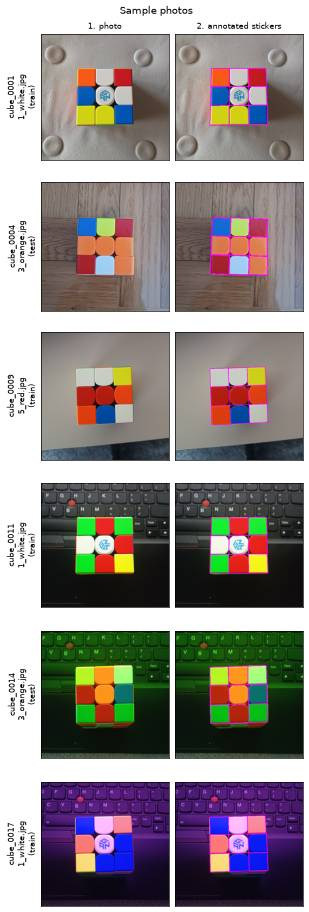

In [37]:
show_stages(
    lambda photo, image, st: (
        st.add("photo", photo),
        st.add("annotated stickers", lambda: draw(photo, truth_polygons(image))),
    ),
    "Sample photos",
)

## Measurements

On the training photos, from the annotations; they set the grids below.

- **Seams** – the annotated face is rectified (`GRID_SIZE` square); the mean gray level over
  the rows (x) and the columns (y) is a profile with dark valleys at the seams. A seam is the
  deepest point within 1/3 +- 1/6 and 2/3 +- 1/6; its depth is measured from the darker of
  the two neighboring sticker centers (median of the profile within +- 0.08), so a seam
  between a bright and a dark row is not widened by the dark side; its width is where the
  profile is below half its depth. Widths in rectified px and in photo px (times the mean side of the face /
  `GRID_SIZE`); offset of the seam from 1/3 or 2/3 as a fraction of the side.
- **Stickers** – annotated polygons: side (sqrt of the area), area / photo, aspect (longer /
  shorter side of the minimal rotated rectangle).
- **Faces** – annotated outlines: area / photo, aspect, and the largest / smallest sticker
  area within the face.

Figure: 1. annotated face, 2. rectified, 3. profiles with the measured seam widths marked
below them.

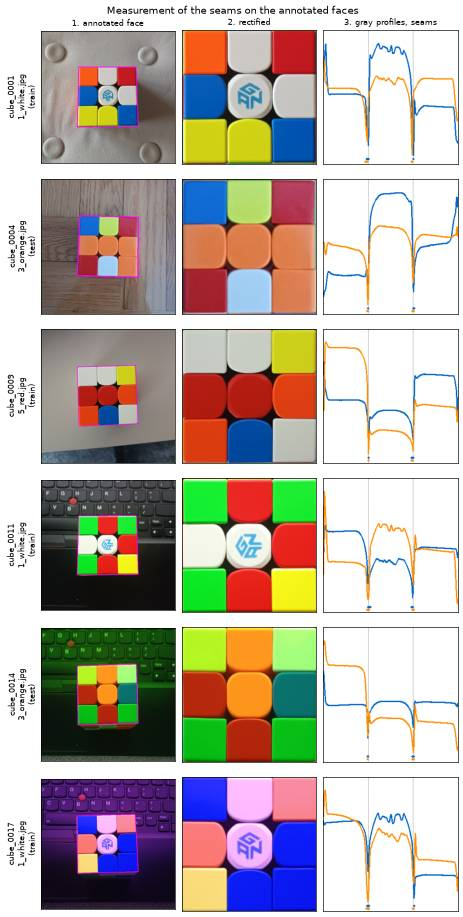

In [38]:
def seam_widths(profile):
    """Valleys near 1/3 and 2/3: width at half depth (rectified px), offset, span"""
    positions = np.arange(GRID_SIZE) / GRID_SIZE

    def plateau(center):
        return np.median(profile[np.abs(positions - center) < 0.08])

    out = []
    for expected in (1 / 3, 2 / 3):
        lo, hi = int((expected - 1 / 6) * GRID_SIZE), int((expected + 1 / 6) * GRID_SIZE)
        i = lo + int(profile[lo:hi].argmin())
        level = min(plateau(expected - 1 / 6), plateau(expected + 1 / 6))
        half = (level + profile[i]) / 2
        left, right = i, i
        while left > lo and profile[left - 1] < half:
            left -= 1
        while right < hi - 1 and profile[right + 1] < half:
            right += 1
        out.append(
            {"seam width, rectified px": right - left + 1, "seam offset": i / GRID_SIZE - expected}
            | {"span": (left, right)}
        )
    return out


def annotated_face(image):
    photo = load(image)
    quad = quadrilateral(scaled(image.outlines[0], image))
    face, _ = rectify(photo, quad)
    gray = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY).astype(np.float32)
    return quad, face, (gray.mean(axis=0), gray.mean(axis=1))


def measure(image):
    photo_area = np.prod(load(image).shape[:2])
    quad, _, profiles = annotated_face(image)
    side = np.mean(np.linalg.norm(quad - np.roll(quad, 1, axis=0), axis=1))
    seams = [
        {name: value for name, value in seam.items() if name != "span"}
        | {"seam width, px": seam["seam width, rectified px"] * side / GRID_SIZE}
        for profile in profiles
        for seam in seam_widths(profile)
    ]
    stickers = []
    for polygon in truth_polygons(image):
        _, (w, h), _ = cv2.minAreaRect(polygon)
        area = cv2.contourArea(polygon)
        stickers.append(
            {
                "side, px": np.sqrt(area),
                "area / photo": area / photo_area,
                "aspect": max(w, h) / min(w, h),
            }
        )
    _, (w, h), _ = cv2.minAreaRect(quad)
    areas = [s["area / photo"] for s in stickers]
    face = {
        "area / photo": cv2.contourArea(quad) / photo_area,
        "aspect": max(w, h) / min(w, h),
        "sticker area max / min": max(areas) / min(areas),
    }
    return seams, stickers, face


def measurement_stages(photo, image, st):
    quad, face, profiles = annotated_face(image)
    st.add("annotated face", lambda: draw(photo, [quad]))
    st.add("rectified", face)
    spans = [(i, *seam["span"]) for i, p in enumerate(profiles) for seam in seam_widths(p)]
    st.add("gray profiles, seams", lambda: profile_panel(profiles, spans=spans))


show_stages(measurement_stages, "Measurement of the seams on the annotated faces")

In [39]:
measured = [measure(image) for image in tqdm(SETS["train"], desc="measure")]
seams = pd.DataFrame([s for m in measured for s in m[0]])
stickers = pd.DataFrame([s for m in measured for s in m[1]])
faces = pd.DataFrame([m[2] for m in measured])
QUANTILES = [0, 0.05, 0.5, 0.95, 1]
pd.concat(
    {name: df.quantile(QUANTILES).T for name, df in
     {"seams": seams, "stickers": stickers, "faces": faces}.items()}
).round(4)  # fmt: skip

measure: 100%|██████████| 126/126 [00:09<00:00, 13.40it/s]


0.00     0.05     0.50      0.95  \
seams    seam width, rectified px   1.0000   2.0000   6.0000   16.0000   
         seam offset               -0.0267  -0.0067   0.0000    0.0100   
         seam width, px             0.3759   1.4667   3.8612   17.2406   
stickers side, px                  34.4964  37.4943  75.0367  102.6144   
         area / photo               0.0016   0.0019   0.0075    0.0140   
         aspect                     1.0000   1.0000   1.0298    1.0935   
faces    area / photo               0.0151   0.0177   0.0734    0.1821   
         aspect                     1.0000   1.0004   1.0212    1.0600   
         sticker area max / min     1.0586   1.0756   1.1460    1.2966   

                                       1.00  
seams    seam width, rectified px   22.0000  
         seam offset                 0.0300  
         seam width, px             22.1978  
stickers side, px                  119.4634  
         area / photo                0.0190  
         aspect                      1.1497  
faces    area / photo                0.2270  
         aspect                      1.0733  
         sticker area max / min      1.3544

Derived values, used by the grids:

- `SEAM`, `SEAM_RECT` – median seam width in photo and rectified px: kernels of erosion,
  blur, dilation and the gradient scale are around it, black-hat kernels above it
- `STICKER` – median sticker side: the closing that fills a white sticker (F1)
- `MIN_AREA`, `MAX_AREA` – half the smallest, twice the largest sticker area / photo: the
  sticker size check of K and the area range of MSER (a region may lack the rim of a sticker
  or include its seam; the whole face is excluded)
- `FACE_MIN_AREA` – half the smallest face area / photo (F2)
- 95th and 99th percentiles of the aspect of stickers (K) and faces (F2), of the sticker area
  ratio within a face (G) and of the seam offsets (R) – in the grids directly

In [40]:
SEAM = seams["seam width, px"].median()
SEAM_RECT = seams["seam width, rectified px"].median()
STICKER = stickers["side, px"].median()
MIN_AREA = 0.5 * stickers["area / photo"].min()
MAX_AREA = 2 * stickers["area / photo"].max()
FACE_MIN_AREA = 0.5 * faces["area / photo"].min()
pd.Series(
    {"SEAM": SEAM, "SEAM_RECT": SEAM_RECT, "STICKER": STICKER, "MIN_AREA": MIN_AREA}
    | {"MAX_AREA": MAX_AREA, "FACE_MIN_AREA": FACE_MIN_AREA}
).round(5)

SEAM              3.86116
SEAM_RECT         6.00000
STICKER          75.03666
MIN_AREA          0.00079
MAX_AREA          0.03806
FACE_MIN_AREA     0.00756
dtype: float64

## K: shape filter

Decides whether a closed contour is a sticker. First the size: area from `MIN_AREA` to
`MAX_AREA` of the photo; contours of another size are dropped and not shown. Then the shape,
from ICCVG06: moments of the region and its compactness.

- `M1 = (mu20 + mu02) / m00^2` – spread (smallest for a circle)
- `M2 = ((mu20 - mu02)^2 + 4 mu11^2) / m00^4` – elongation (0 for a square or a circle)
- `M3 = ((mu30 - 3 mu12)^2 + (3 mu21 - mu03)^2) / m00^5` – asymmetry (0 for symmetric shapes)
- `M7 = (mu20 mu02 - mu11^2) / m00^4` – determinant of the covariance
- `gamma = L / (2 sqrt(pi S)) - 1` – compactness, L perimeter, S area (0 for a circle)

The paper's limits `M1 >= 1.0`, `M2 <= 2.5`, `M3 <= 0.5`, `M7 >= 0.1` cannot hold with these
formulas: a square has M1 = 1/6 and M7 = 1/144. Its normalization is unknown, so the limits
come from reference shapes. Accepted: square, circle (rounded corners) and a rectangle of
aspect `rect_ratio`; limits: M1 and M2 at most the largest of them, M7 at least the smallest.
Rejected: stickers of one color merged into a 1 x 2 rectangle or an L; M3 at most
`m3_fraction` of the L's (M3 is 0 for the accepted shapes). Gamma at most `gamma_max`.

**Grid** (`K_GRID`), tuned separately with each S method:

- `rect_ratio` – 95th and 99th percentile of the aspect of the annotated stickers, and 1.25,
  1.5, 1.75 x the 99th (contours of the methods are rougher than the annotations; below 2,
  two merged stickers)
- `m3_fraction` – 0.025, 0.05, 0.1, 0.25, 0.5
- `gamma_max` – 0.2, 0.3, 0.4 (the paper), 0.5

{'rect_ratio': [np.float64(1.09), np.float64(1.12), np.float64(1.4), np.float64(1.68), np.float64(1.96)], 'm3_fraction': [0.025, 0.05, 0.1, 0.25, 0.5], 'gamma_max': [0.2, 0.3, 0.4, 0.5]}


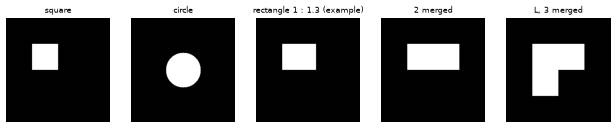

,M1,M2,M3,M7,gamma
square,0.16667,0.00000,0.00000,0.00694,0.12838
circle,0.15918,0.00000,0.00000,0.00633,0.06165
rectangle 1 : 1.3 (example),0.17261,0.00202,0.00000,0.00694,0.13839
2 merged,0.20940,0.01607,0.00000,0.00694,0.19852
"L, 3 merged",0.20495,0.00567,0.00264,0.00908,0.30498


In [41]:
FEATURES = ("M1", "M2", "M3", "M7", "gamma")


def shape_features(contour):
    contour = np.int32(contour).reshape(-1, 1, 2)
    m = cv2.moments(contour)
    m00 = m["m00"] or 1e-9
    perimeter = cv2.arcLength(contour, closed=True)
    return {
        "M1": (m["mu20"] + m["mu02"]) / m00**2,
        "M2": ((m["mu20"] - m["mu02"]) ** 2 + 4 * m["mu11"] ** 2) / m00**4,
        "M3": ((m["mu30"] - 3 * m["mu12"]) ** 2 + (3 * m["mu21"] - m["mu03"]) ** 2) / m00**5,
        "M7": (m["mu20"] * m["mu02"] - m["mu11"] ** 2) / m00**4,
        "gamma": perimeter / (2 * np.sqrt(np.pi * m00)) - 1,
    }


def feature_array(contours):
    rows = [[f[name] for name in FEATURES] for f in map(shape_features, contours)]
    return np.array(rows, np.float64).reshape(-1, len(FEATURES))


def reference_mask(cells, side=60):
    # union of grid cells (column, row)
    mask = np.zeros((4 * side, 4 * side), np.uint8)
    for col, row in cells:
        mask[(row + 1) * side : (row + 2) * side, (col + 1) * side : (col + 2) * side] = 1
    return mask


def rectangle_mask(ratio, side=60):
    mask = np.zeros((4 * side, 4 * side), np.uint8)
    cv2.rectangle(mask, (side, side), (side + round(ratio * side) - 1, 2 * side - 1), 1, -1)
    return mask


REFERENCE_MASKS = {
    "square": reference_mask([(0, 0)]),
    "circle": cv2.circle(np.zeros((240, 240), np.uint8), (120, 120), 40, 1, -1),
    "rectangle 1 : 1.3 (example)": rectangle_mask(1.3),
    "2 merged": reference_mask([(0, 0), (1, 0)]),
    "L, 3 merged": reference_mask([(0, 0), (1, 0), (0, 1)]),
}
REFERENCES = {name: shape_features(contour_of(m)) for name, m in REFERENCE_MASKS.items()}


@functools.cache
def _k_limits(rect_ratio, m3_fraction, gamma_max):
    rectangle = shape_features(contour_of(rectangle_mask(rect_ratio)))
    accepted = [REFERENCES["square"], REFERENCES["circle"], rectangle]
    return {
        "M1": max(s["M1"] for s in accepted),
        "M2": max(s["M2"] for s in accepted),
        "M3": m3_fraction * REFERENCES["L, 3 merged"]["M3"],
        "M7": min(s["M7"] for s in accepted),
        "gamma": gamma_max,
    }


def k_limits(p):
    return _k_limits(p["rect_ratio"], p["m3_fraction"], p["gamma_max"])


def shape_ok(features, limits):
    m1, m2, m3, m7, gamma = features.T
    return (
        (m1 <= limits["M1"]) & (m2 <= limits["M2"]) & (m3 <= limits["M3"])
        & (m7 >= limits["M7"]) & (gamma >= 0) & (gamma <= limits["gamma"])
    )  # fmt: skip


def describe(contours, photo):
    """Contours of a sticker size and their shape features"""
    area = photo.shape[0] * photo.shape[1]
    sized = [
        c for c in contours if MIN_AREA * area <= cv2.contourArea(np.int32(c)) <= MAX_AREA * area
    ]
    return sized, feature_array(sized)


aspect_99 = stickers.aspect.quantile(0.99)
K_GRID = {
    "rect_ratio": sorted(
        {round(stickers.aspect.quantile(0.95), 2), round(aspect_99, 2)}
        | {round(f * aspect_99, 2) for f in (1.25, 1.5, 1.75)}
    ),
    "m3_fraction": [0.025, 0.05, 0.1, 0.25, 0.5],
    "gamma_max": [0.2, 0.3, 0.4, 0.5],
}
print(K_GRID)

fig, axes = plt.subplots(1, len(REFERENCE_MASKS), figsize=(2.6 * len(REFERENCE_MASKS), 3))
for ax, (name, mask) in zip(axes, REFERENCE_MASKS.items(), strict=True):
    ax.imshow(mask, cmap="gray")
    ax.set_title(name, fontsize=10)
    ax.set_axis_off()
plt.show()
pd.DataFrame(REFERENCES).T.round(5)

## Part A: single stickers

An S method returns all closed contours of its last stage; `cells` applies the filter K
(stage *shape filter K*: green accepted, red rejected) and, for S3, removes duplicates.

In [42]:
def without_duplicates(indices, areas, threshold, pair_iou):
    """Largest first; a region overlapping a kept one with IoU > threshold is dropped"""
    kept = []
    for i in sorted(indices, key=lambda i: -areas[i]):
        if all(pair_iou(i, j) <= threshold for j in kept):
            kept.append(i)
    return kept


def cells(contours, photo, p, st=NO_STAGES):
    sized, features = describe(contours, photo)
    ok = shape_ok(features, k_limits(p))
    accepted = [c for c, a in zip(sized, ok, strict=True) if a]
    rejected = [c for c, a in zip(sized, ok, strict=True) if not a]
    st.add("shape filter K", lambda: draw_decisions(photo, accepted, rejected))
    if "duplicate_iou" in p:
        areas = [cv2.contourArea(np.int32(c)) for c in accepted]
        kept = without_duplicates(
            range(len(accepted)),
            areas,
            p["duplicate_iou"],
            lambda i, j: polygon_iou(accepted[i], accepted[j]),
        )
        accepted = [accepted[i] for i in kept]
        st.add("duplicates removed", lambda: draw(photo, accepted, ACCEPTED))
    return accepted


S_METHODS = {}  # name -> (contours function, fixed parameters)


def run_cells(name, photo, st=NO_STAGES):
    contours_of, fixed = S_METHODS[name]
    p = fixed | BEST[name]
    return cells(contours_of(photo, p, st), photo, p, st)


@functools.cache
def best_cells(name, image_key):
    return run_cells(name, load(IMAGES[image_key]))


def tune_cells(name, grid):
    """Upstream: parameters of the contours; K and duplicate_iou are scored on them"""
    contours_of, fixed = S_METHODS[name]
    upstream = [n for n in grid if n not in K_GRID and n != "duplicate_iou"]

    def prepare(image, up):
        photo = load(image)
        sized, features = describe(contours_of(photo, fixed | up, NO_STAGES), photo)
        areas = [cv2.contourArea(np.int32(c)) for c in sized]
        memo = {}

        def pair_iou(i, j):
            if (i, j) not in memo:
                memo[i, j] = polygon_iou(sized[i], sized[j])
            return memo[i, j]

        return features, match(sized, truth_polygons(image)), areas, pair_iou

    def score(prepared, p):
        limits, counts = k_limits(p), []
        for features, hits, areas, pair_iou in prepared:
            accepted = list(np.flatnonzero(shape_ok(features, limits)))
            if "duplicate_iou" in p:
                accepted = without_duplicates(accepted, areas, p["duplicate_iou"], pair_iou)
            counts.append((found_count(hits[accepted]), len(accepted)))
        return f1_score(counts)

    BEST[name] = tune(name, grid, prepare, score, upstream)
    best_cells.cache_clear()


def stage_variants(names, picks, run):
    """Chosen stages of several variants side by side"""

    def stages(photo, image, st):
        for name in names:
            sub = Stages(show=True)
            run(name, photo, sub)
            for pick in picks:
                if pick in sub:
                    st.add(f"{name}: {pick}", sub[pick])

    return stages

### S1: ICCVG06 (Kasprzak, Szynkiewicz, Czajka 2006)

Pixels are classified into the 6 colors, connected regions of one color are candidates, the
filter K keeps stickers. Stickers are separated by pixels of no color (dark seams) and by the
erosion.

**Input:** photo · **Output:** sticker contours

1. **Photo** (**gray world** in that variant: B, G, R scaled to equal means)
2. **U'** – YUV; chroma scaled by intensity (eq. 1-3): `U' = (U - 128) k + 128` with
   `k = 128 / Y` for `Y > 128`, `k = (256 - Y) / 128` for `Y < 128`
3. **V'** – the same for V
4. **Pixel colors** – a pixel gets a color if its Y is within the color's interval and U', V'
   within mean +- 3 sigma; overlaps, not covered by the paper: the nearest mean in (U', V');
   black: no color
5. **Erosion** – of each color mask, `opening` x `opening`: removes noise, widens seams
6. **Dilation** – the same kernel: restores the regions, separated ones stay separated
7. **Contours** – outer contours of the regions of each color
8. **Shape filter K**

**Variants** (the intervals of stage 4): **Table 1** of the paper; **gray world** – Table 1
after stage 1 gray world (against colored light); **fitted** – intervals from the pixels of
the annotated stickers of the training photos: Y from the 1st to the 99th percentile, U' and
V' mean +- 3 sigma.

**Grid:** `opening` – odd sizes nearest to `SEAM` / 2, `SEAM`, 2, 3 and 4 `SEAM` (the paper
gives no size), and `K_GRID`. Table 1 itself is not tuned: it is the paper's.

In [43]:
DISPLAY = {  # BGR
    "white": (255, 255, 255),
    "green": (0, 160, 0),
    "orange": (0, 130, 255),
    "blue": (200, 60, 0),
    "red": (40, 30, 220),
    "yellow": (0, 210, 230),
}
COLORS = list(DISPLAY)
TABLE_1 = {  # Y min, Y max, U' mean, U' 3 sigma, V' mean, V' 3 sigma
    "red": (50, 140, 110, 38, 205, 45),
    "orange": (140, 210, 100, 48, 205, 45),
    "blue": (70, 240, 195, 55, 55, 55),
    "green": (70, 240, 70, 65, 60, 50),
    "white": (190, 255, 128, 12, 128, 11),
    "yellow": (118, 150, 90, 25, 140, 20),
}
TABLES = {"Table 1": TABLE_1}


def normalized_yuv(photo):
    y, u, v = cv2.split(cv2.cvtColor(photo, cv2.COLOR_BGR2YUV).astype(np.float32))
    kappa = np.ones_like(y)
    bright, dark = y > 128, y < 128
    kappa[bright] = 128 / y[bright]
    kappa[dark] = (256 - y[dark]) / 128
    return y, (u - 128) * kappa + 128, (v - 128) * kappa + 128


def classify(y, u, v, table):
    """Color index per pixel, -1 for none"""
    best = np.full(y.shape, np.inf, np.float32)
    labels = np.full(y.shape, -1, np.int8)
    for name, (y_min, y_max, u_mean, u_dev, v_mean, v_dev) in table.items():
        inside = (
            (y >= y_min) & (y <= y_max)
            & (np.abs(u - u_mean) <= u_dev) & (np.abs(v - v_mean) <= v_dev)
        )  # fmt: skip
        distance = np.hypot((u - u_mean) / u_dev, (v - v_mean) / v_dev)
        better = inside & (distance < best)
        best[better], labels[better] = distance[better], COLORS.index(name)
    return labels


def paint(masks):
    out = np.zeros((*masks[0].shape, 3), np.uint8)
    for name, mask in zip(COLORS, masks, strict=True):
        out[mask > 0] = DISPLAY[name]
    return out


def gray_world(photo):
    means = photo.reshape(-1, 3).mean(axis=0)
    return np.clip(photo * (means.mean() / means), 0, 255).astype(np.uint8)


def s1_contours(photo, p, st=NO_STAGES):
    if p["white_balance"]:
        photo = gray_world(photo)
        st.add("gray world", photo)
    else:
        st.add("photo", photo)
    y, u, v = normalized_yuv(photo)
    st.add("U'", lambda: gray8(u))
    st.add("V'", lambda: gray8(v))
    labels = classify(y, u, v, TABLES[p["table"]])
    masks = [np.uint8(labels == i) for i in range(len(COLORS))]
    st.add("pixel colors", lambda: paint(masks))
    kernel = np.ones((p["opening"], p["opening"]), np.uint8)
    eroded = [cv2.erode(m, kernel) for m in masks]
    st.add("erosion", lambda: paint(eroded))
    opened = [cv2.dilate(m, kernel) for m in eroded]
    st.add("dilation", lambda: paint(opened))
    contours = [
        c for m in opened for c in cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]
    ]
    st.add("contours", lambda: draw(paint(opened), contours, (255, 0, 255), 1))
    return contours


def fit_table(subset):
    pixels = {name: [] for name in COLORS}
    for image in subset:
        photo = load(image)
        yuv = np.stack(normalized_yuv(photo), axis=-1)
        for sticker in image.stickers:
            mask = fill(photo.shape, scaled(sticker.polygon, image)).astype(np.uint8)
            mask = cv2.erode(mask, np.ones((7, 7), np.uint8)).astype(bool)
            pixels[COLOR[sticker.color]].append(yuv[mask])
    table = {}
    for name, chunks in pixels.items():
        y, u, v = np.concatenate(chunks).T
        y_min, y_max = np.percentile(y, [1, 99])
        table[name] = (y_min, y_max, u.mean(), 3 * u.std(), v.mean(), 3 * v.std())
    return table


TABLES["fitted"] = fit_table(SETS["train"])
S_METHODS |= {
    "S1, Table 1": (s1_contours, {"table": "Table 1", "white_balance": False}),
    "S1, gray world": (s1_contours, {"table": "Table 1", "white_balance": True}),
    "S1, fitted": (s1_contours, {"table": "fitted", "white_balance": False}),
}
S1_GRID = {"opening": odds([SEAM / 2, SEAM, 2 * SEAM, 3 * SEAM, 4 * SEAM])} | K_GRID
pd.DataFrame(TABLES).map(lambda t: np.round(t).astype(int))

,Table 1,fitted
red,"[50, 140, 110, 38, 205, 45]","[31, 128, 91, 43, 259, 78]"
orange,"[140, 210, 100, 48, 205, 45]","[47, 188, 78, 36, 235, 103]"
blue,"[70, 240, 195, 55, 55, 55]","[19, 113, 194, 92, 60, 88]"
green,"[70, 240, 70, 65, 60, 50]","[44, 175, 106, 49, 37, 88]"
white,"[190, 255, 128, 12, 128, 11]","[61, 249, 126, 30, 132, 41]"
yellow,"[118, 150, 90, 25, 140, 20]","[51, 241, 76, 34, 146, 38]"


In [44]:
for name in ("S1, Table 1", "S1, gray world", "S1, fitted"):
    tune_cells(name, S1_GRID)

S1, Table 1: 100%|██████████| 5/5 [00:45<00:00,  9.11s/it]

S1, Table 1: 500 combinations, best score 0.618


,opening,rect_ratio,m3_fraction,gamma_max,score
155,3,1.40,0.25,0.5,0.617718
159,3,1.40,0.50,0.5,0.617718
275,7,1.68,0.25,0.5,0.616667
255,7,1.40,0.25,0.5,0.616587
151,3,1.40,0.10,0.5,0.616413


S1, gray world: 100%|██████████| 5/5 [00:56<00:00, 11.32s/it]

S1, gray world: 500 combinations, best score 0.608


,opening,rect_ratio,m3_fraction,gamma_max,score
155,3,1.4,0.25,0.5,0.608430
159,3,1.4,0.50,0.5,0.608059
258,7,1.4,0.50,0.4,0.607533
259,7,1.4,0.50,0.5,0.607533
254,7,1.4,0.25,0.4,0.606947


S1, fitted: 100%|██████████| 5/5 [00:47<00:00,  9.50s/it]

S1, fitted: 500 combinations, best score 0.744


,opening,rect_ratio,m3_fraction,gamma_max,score
151,3,1.40,0.10,0.5,0.744399
155,3,1.40,0.25,0.5,0.743087
159,3,1.40,0.50,0.5,0.742714
147,3,1.40,0.05,0.5,0.740360
171,3,1.68,0.10,0.5,0.739065


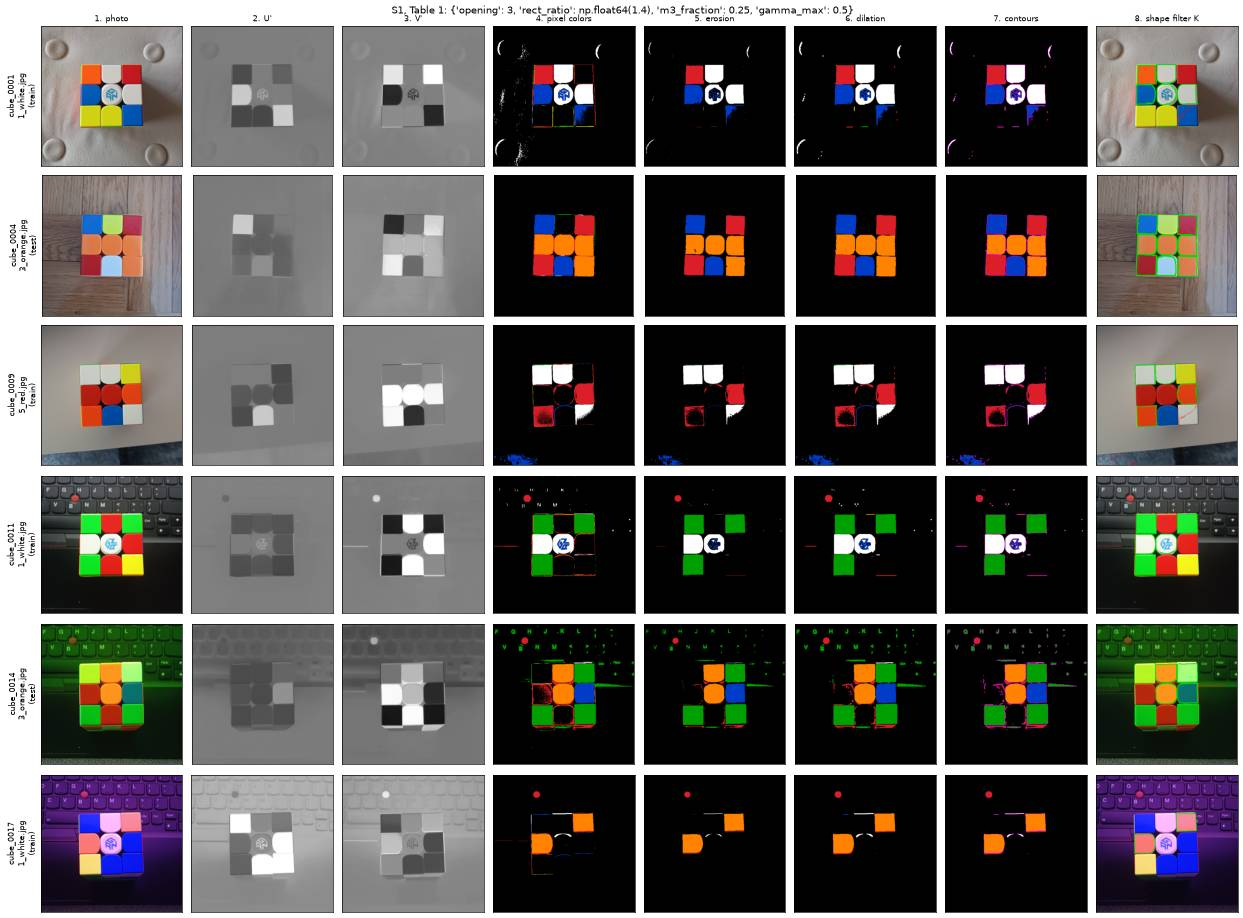

In [45]:
show_stages(
    lambda photo, _, st: run_cells("S1, Table 1", photo, st),
    f"S1, Table 1: {BEST['S1, Table 1']}",
)

Histograms of U' and V' of the first sample (Fig. 4 of the paper): the background dominates,
peaks of the sticker colors appear after the normalization.

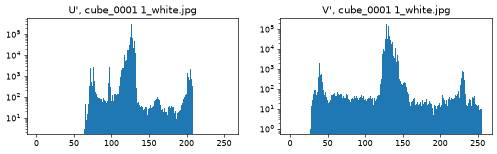

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.5))
_, u, v = normalized_yuv(photos[0])
for ax, channel, name in zip(axes, (u, v), ("U'", "V'"), strict=True):
    ax.hist(channel.ravel(), bins=256, range=(0, 256), log=True)
    ax.set_title(f"{name}, {samples[0].cube_id} {samples[0].file_name}")
plt.show()

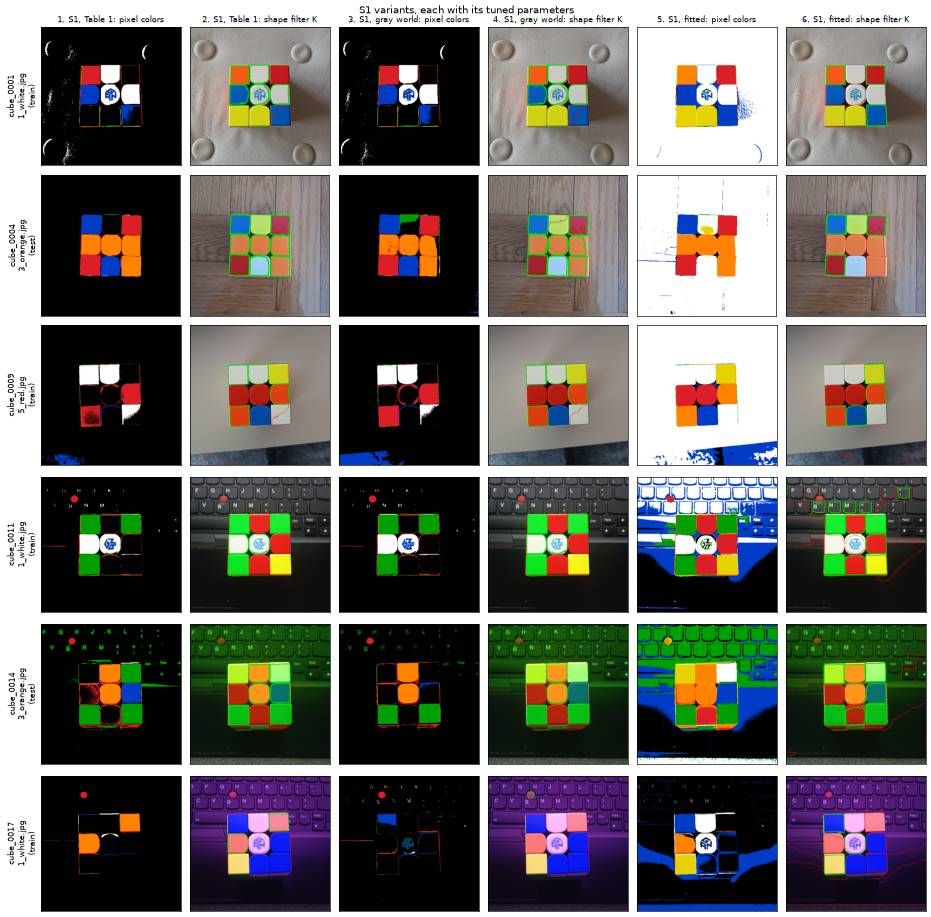

In [47]:
show_stages(
    stage_variants(
        ["S1, Table 1", "S1, gray world", "S1, fitted"],
        ["pixel colors", "shape filter K"],
        run_cells,
    ),
    "S1 variants, each with its tuned parameters",
)

### S2: Canny edges

Seams between the pieces are dark lines, also between stickers of one color, so regions
enclosed by edges are sticker candidates.

**Input:** photo · **Output:** sticker contours

1. **Gray** – luminance (variant **Lab**: **blur** first – Gaussian, sigma `sigma`; then
   **Lab: L**, the photo in Lab, shown: L; and **gradient**, the Sobel magnitude, maximum
   over L, a, b, shown for comparison with S3)
2. **Blur** – Gaussian `blur` x `blur`, removes fine texture (gray only)
3. **Canny** – thresholds `canny_low` and `canny_low` x `canny_ratio`. Gray: Canny's own
   Sobel derivatives of the blurred gray image. Lab: the Sobel derivatives of L, a, b are
   given to Canny (`cv2.Canny(dx, dy, ...)`), which takes in every pixel the channel of the
   largest magnitude (L2 norm): a border of two colors of similar lightness is an edge too
4. **Dilation** – `dilation` x `dilation`. A Canny edge is a line of 1 px, connected also
   diagonally; the regions off the edges are connected diagonally too and leak through its
   diagonal steps, so no region would be closed. Dilation of at least 3 x 3 closes them
5. **Regions** – connected areas off the edges, each in its own color
6. **Shape filter K**

**Variants:** **gray** – Canny of the gray image; **Lab** – Canny of the Lab gradient, as in
S3 (the gradient image itself is not given to Canny: Canny differentiates its input, the
gradient of a gradient has an edge on both slopes of every seam).

**Grid:** `blur` (gray) – odd sizes nearest to `SEAM` / 2, `SEAM`, 2 `SEAM`; `sigma` (Lab) –
`SEAM` / 2, `SEAM`, 2 `SEAM`; `canny_low` – 10, 20, 40, 60, 80; `canny_ratio` – 2, 3 (Canny's
recommended range); `dilation` – 3, 5 (3 is the least that closes the regions, see stage 4);
`K_GRID`.

In [48]:
def edge_map(photo, p, st=NO_STAGES):
    """Stages 1-4 of S2, also used by F2"""
    low, high = p["canny_low"], p["canny_low"] * p["canny_ratio"]
    if p["source"] == "gray":
        gray = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)
        st.add("gray", gray)
        blurred = cv2.GaussianBlur(gray, (p["blur"], p["blur"]), 0)
        st.add("blur", blurred)
        canny = cv2.Canny(blurred, low, high)
    else:
        blurred = cv2.GaussianBlur(photo, (0, 0), p["sigma"])
        st.add("blur", blurred)
        lab = cv2.cvtColor(blurred, cv2.COLOR_BGR2Lab)
        st.add("Lab: L", lab[..., 0])
        dx, dy = cv2.Sobel(lab, cv2.CV_16S, 1, 0), cv2.Sobel(lab, cv2.CV_16S, 0, 1)
        st.add("gradient", lambda: lab_gradient_panel(dx, dy))
        canny = cv2.Canny(dx, dy, low, high, L2gradient=True)
    st.add("Canny", canny)
    dilated = cv2.dilate(canny, np.ones((p["dilation"], p["dilation"]), np.uint8))
    st.add("dilation", dilated)
    return dilated


def lab_gradient_panel(dx, dy):
    magnitude = np.hypot(dx.astype(np.float32), dy.astype(np.float32)).max(axis=2)
    return gray8(magnitude / np.percentile(magnitude, 99) * 255)


def s2_contours(photo, p, st=NO_STAGES):
    off_edges = 255 - edge_map(photo, p, st)
    st.add("regions", lambda: random_colors(cv2.connectedComponents(off_edges)[1]))
    contours, _ = cv2.findContours(off_edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
    return contours


CANNY_GRID = {"canny_low": [10, 20, 40, 60, 80], "canny_ratio": [2, 3], "dilation": [3, 5]}
EDGE_GRIDS = {  # variant -> grid of edge_map
    "gray": {"blur": odds([SEAM / 2, SEAM, 2 * SEAM])} | CANNY_GRID,
    "Lab": {"sigma": [round(SEAM / 2, 2), round(SEAM, 2), round(2 * SEAM, 2)]} | CANNY_GRID,
}
for source, grid in EDGE_GRIDS.items():
    S_METHODS[f"S2, {source}"] = (s2_contours, {"source": source})
    tune_cells(f"S2, {source}", grid | K_GRID)

S2, gray: 100%|██████████| 60/60 [01:56<00:00,  1.95s/it]

S2, gray: 6000 combinations, best score 0.929


,blur,canny_low,canny_ratio,dilation,rect_ratio,m3_fraction,gamma_max,score
2948,3,40,2,5,1.4,0.10,0.2,0.928760
1349,1,60,2,5,1.4,0.10,0.3,0.927817
2952,3,40,2,5,1.4,0.25,0.2,0.927129
2956,3,40,2,5,1.4,0.50,0.2,0.927129
2949,3,40,2,5,1.4,0.10,0.3,0.925990


S2, Lab: 100%|██████████| 60/60 [02:24<00:00,  2.42s/it]

S2, Lab: 6000 combinations, best score 0.884


,sigma,canny_low,canny_ratio,dilation,rect_ratio,m3_fraction,gamma_max,score
748,1.93,20,3,5,1.4,0.10,0.2,0.884323
745,1.93,20,3,5,1.4,0.05,0.3,0.882843
746,1.93,20,3,5,1.4,0.05,0.4,0.882789
752,1.93,20,3,5,1.4,0.25,0.2,0.881960
756,1.93,20,3,5,1.4,0.50,0.2,0.881960


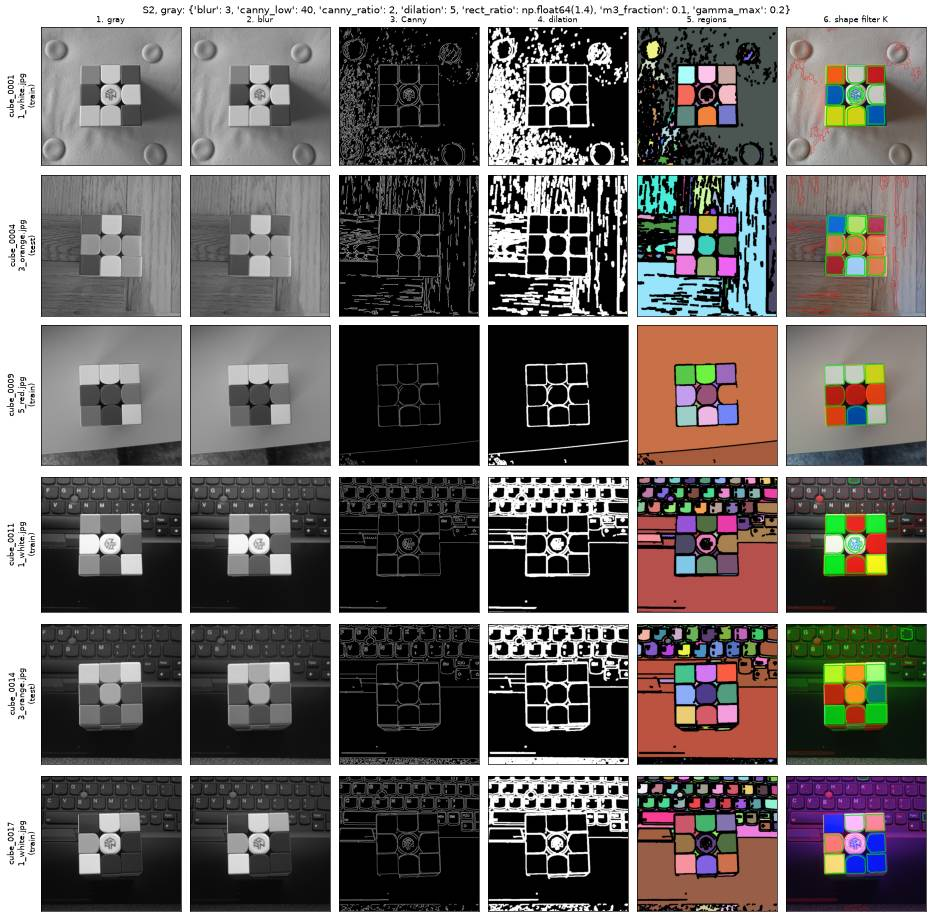

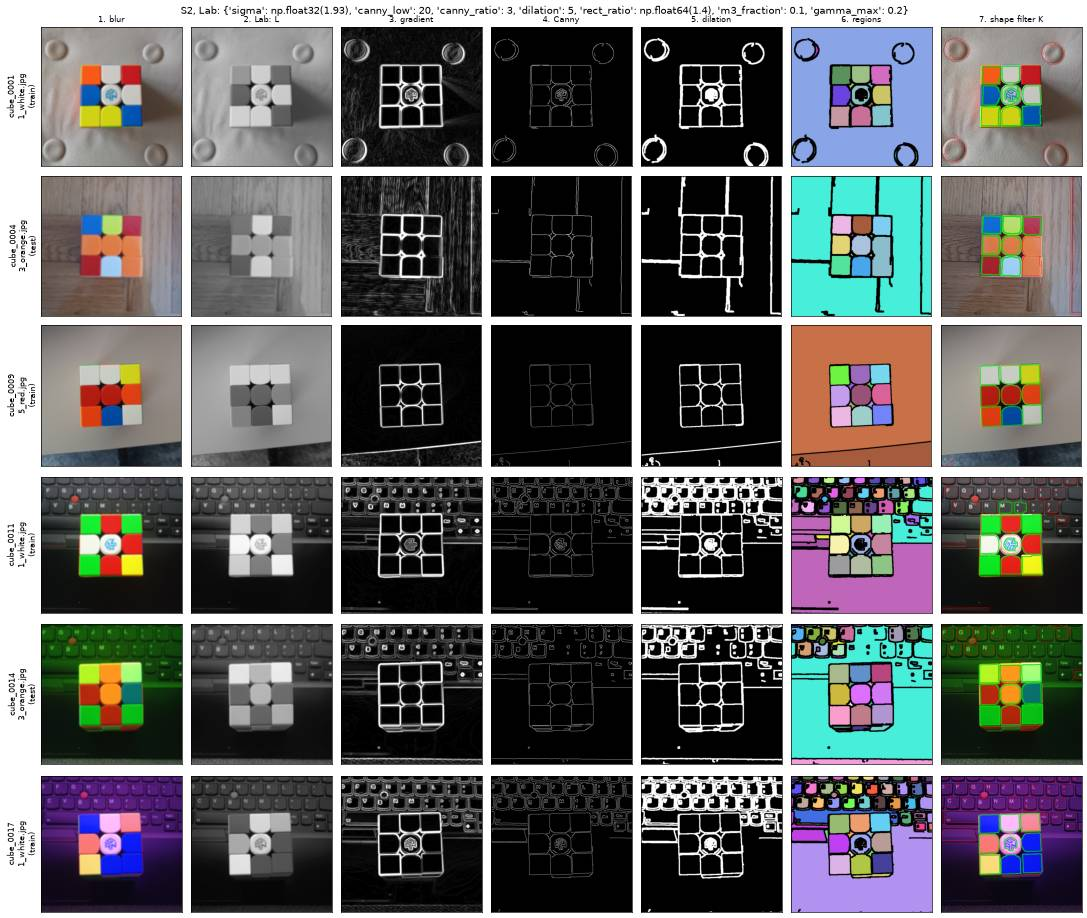

In [49]:
for source in EDGE_GRIDS:
    name = f"S2, {source}"
    show_stages(
        lambda photo, _, st, name=name: run_cells(name, photo, st), f"{name}: {BEST[name]}"
    )

### S3: MSER

MSER (maximally stable extremal regions) thresholds an image at every level and keeps the
connected regions whose area barely changes over `delta` levels. A sticker bounded by seams
is such a region: its area jumps only when the threshold crosses the seam.

On the gradient magnitude a sticker is a basin of low gradient enclosed by a ridge (the
seams). Smooth shading by the light makes only a small gradient, so it does not split the
sticker, and every sticker gets its own threshold (S2 has one Canny threshold per photo).

**Input:** photo · **Output:** sticker contours

1. **Blur** – Gaussian, sigma `sigma`: the scale of the gradient
2. **Lab: L** – the photo in Lab, so that a border of two colors of similar lightness has a
   gradient too; shown: L
3. **Gradient** – Sobel magnitude, maximum over L, a, b; scaled to 0-255 at its
   `GRADIENT_PERCENTILE` percentile (fixed: MSER depends only on the order of the levels, the
   scale changes their quantization and clips the top 1 %, ridge crests)
4. **MSER regions** – each in its own color; area from `MIN_AREA` to `MAX_AREA` of the
   photo; both polarities. `min_diversity`: OpenCV drops a region too similar to its parent
   (default 0.2); a basin grows slowly with the threshold, so 0 is in the grid
5. **Shape filter K** – on the outer contour of each region (holes such as the logo are
   ignored)
6. **Duplicates removed** – regions of neighboring thresholds are nested and nearly equal; of
   accepted regions overlapping with IoU > `duplicate_iou` the largest stays

**Variants** (the image for MSER, stages 1-3 replaced): **gray** – the luminance; **color
(MSCR)** – OpenCV's MSER on the color photo: maximally stable color regions, pixels joined in
the order of the color distance to the neighbor, edges smoothed by `edge_blur`; **gradient**.

**Grid:** `sigma` – `SEAM` / 4, `SEAM` / 2, `SEAM`, 1.5 `SEAM`, 2 `SEAM`; `delta` – 2, 5 (OpenCV's default); `min_diversity` – 0, 0.2 (OpenCV's default);
`edge_blur` (MSCR) – odd sizes nearest to `SEAM` / 2, `SEAM`, 2 `SEAM`; `duplicate_iou` – 0.3,
0.5, 0.7; `K_GRID`.

In [50]:
GRADIENT_PERCENTILE = 99


def gradient(photo, sigma, st=NO_STAGES):
    blurred = cv2.GaussianBlur(photo, (0, 0), sigma)
    st.add("blur", blurred)
    lab = cv2.cvtColor(blurred, cv2.COLOR_BGR2Lab).astype(np.float32)
    st.add("Lab: L", lambda: gray8(lab[..., 0]))
    magnitude = np.max(
        [np.hypot(cv2.Sobel(c, cv2.CV_32F, 1, 0), cv2.Sobel(c, cv2.CV_32F, 0, 1))
         for c in cv2.split(lab)],
        axis=0,
    )  # fmt: skip
    out = gray8(magnitude / np.percentile(magnitude, GRADIENT_PERCENTILE) * 255)
    st.add("gradient", out)
    return out


def region_contour(points):
    corner = points.min(axis=0)
    local = points - corner
    mask = np.zeros(local.max(axis=0)[::-1] + 1, np.uint8)
    mask[local[:, 1], local[:, 0]] = 1
    return contour_of(mask) + corner


def paint_regions(regions, shape):
    out = np.zeros((*shape[:2], 3), np.uint8)
    colors = random_colors(np.arange(len(regions) + 1))[1:]
    for points, color in zip(regions, colors, strict=True):
        out[points[:, 1], points[:, 0]] = color
    return out


def s3_contours(photo, p, st=NO_STAGES):
    area = photo.shape[0] * photo.shape[1]
    sizes = {"min_area": max(1, int(MIN_AREA * area)), "max_area": int(MAX_AREA * area)}
    if p["source"] == "color":
        image = photo
        st.add("color", photo)
        mser = cv2.MSER_create(**sizes, edge_blur_size=p["edge_blur"])
    else:
        if p["source"] == "gray":
            image = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)
            st.add("gray", image)
        else:
            image = gradient(photo, p["sigma"], st)
        mser = cv2.MSER_create(delta=p["delta"], **sizes, min_diversity=p["min_diversity"])
    regions, _ = mser.detectRegions(image)
    st.add("MSER regions", lambda: paint_regions(regions, photo.shape))
    return [region_contour(points) for points in regions]


S3_GRIDS = {
    "S3, gray": {"delta": [2, 5], "min_diversity": [0.0, 0.2]},
    "S3, color": {"edge_blur": odds([SEAM / 2, SEAM, 2 * SEAM])},
    "S3, gradient": {
        "sigma": [round(f * SEAM, 2) for f in (0.25, 0.5, 1, 1.5, 2)],
        "delta": [2, 5],
        "min_diversity": [0.0, 0.2],
    },
}
for name, grid in S3_GRIDS.items():
    S_METHODS[name] = (s3_contours, {"source": name.removeprefix("S3, ")})
    tune_cells(name, grid | {"duplicate_iou": [0.3, 0.5, 0.7]} | K_GRID)

S3, gray: 100%|██████████| 4/4 [00:59<00:00, 14.90s/it]

S3, gray: 1200 combinations, best score 0.710


,delta,min_diversity,duplicate_iou,rect_ratio,m3_fraction,gamma_max,score
627,5,0.0,0.3,1.12,0.05,0.5,0.710123
727,5,0.0,0.5,1.12,0.05,0.5,0.710123
631,5,0.0,0.3,1.12,0.10,0.5,0.709995
635,5,0.0,0.3,1.12,0.25,0.5,0.709995
639,5,0.0,0.3,1.12,0.50,0.5,0.709995


S3, color: 100%|██████████| 3/3 [01:57<00:00, 39.20s/it]

S3, color: 900 combinations, best score 0.784


,edge_blur,duplicate_iou,rect_ratio,m3_fraction,gamma_max,score
631,7,0.3,1.12,0.10,0.5,0.783525
635,7,0.3,1.12,0.25,0.5,0.783525
639,7,0.3,1.12,0.50,0.5,0.783525
731,7,0.5,1.12,0.10,0.5,0.783525
735,7,0.5,1.12,0.25,0.5,0.783525


S3, gradient: 100%|██████████| 20/20 [15:18<00:00, 45.92s/it]

S3, gradient: 6000 combinations, best score 0.960


,sigma,delta,min_diversity,duplicate_iou,rect_ratio,m3_fraction,gamma_max,score
1844,1.93,5,0.0,0.3,1.40,0.05,0.2,0.959518
1848,1.93,5,0.0,0.3,1.40,0.10,0.2,0.956819
1944,1.93,5,0.0,0.5,1.40,0.05,0.2,0.954994
1829,1.93,5,0.0,0.3,1.12,0.10,0.3,0.954729
1833,1.93,5,0.0,0.3,1.12,0.25,0.3,0.954301


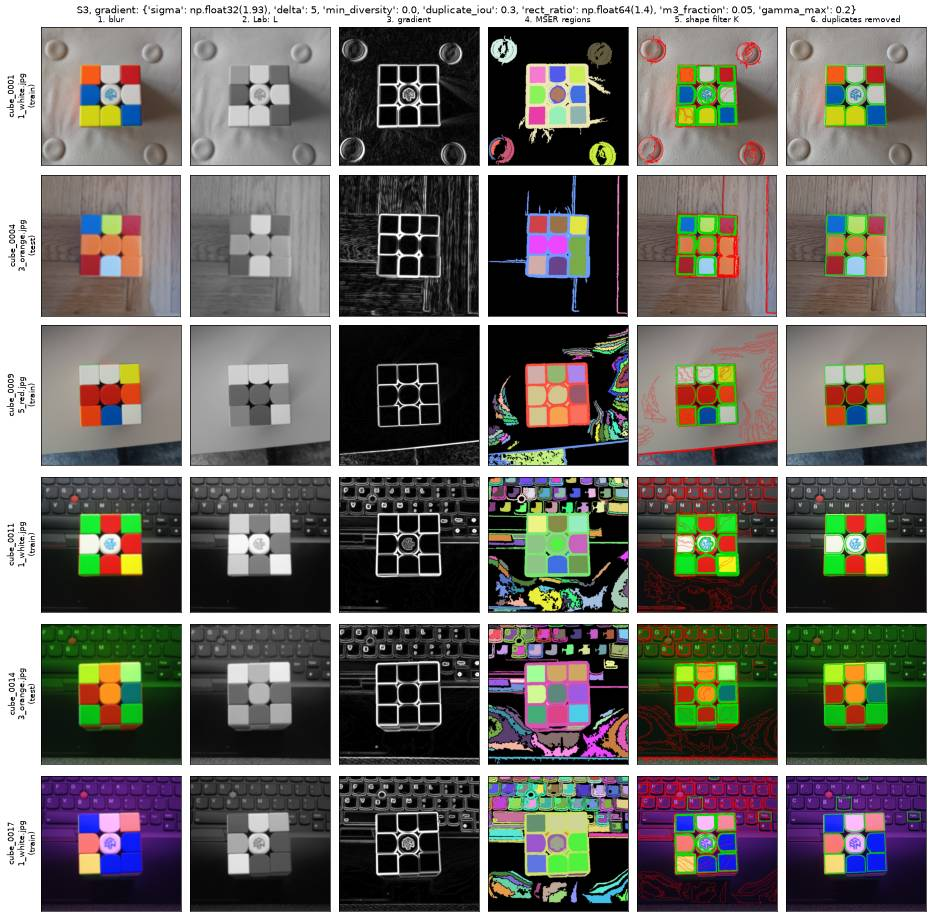

In [51]:
show_stages(
    lambda photo, _, st: run_cells("S3, gradient", photo, st),
    f"S3, gradient: {BEST['S3, gradient']}",
)

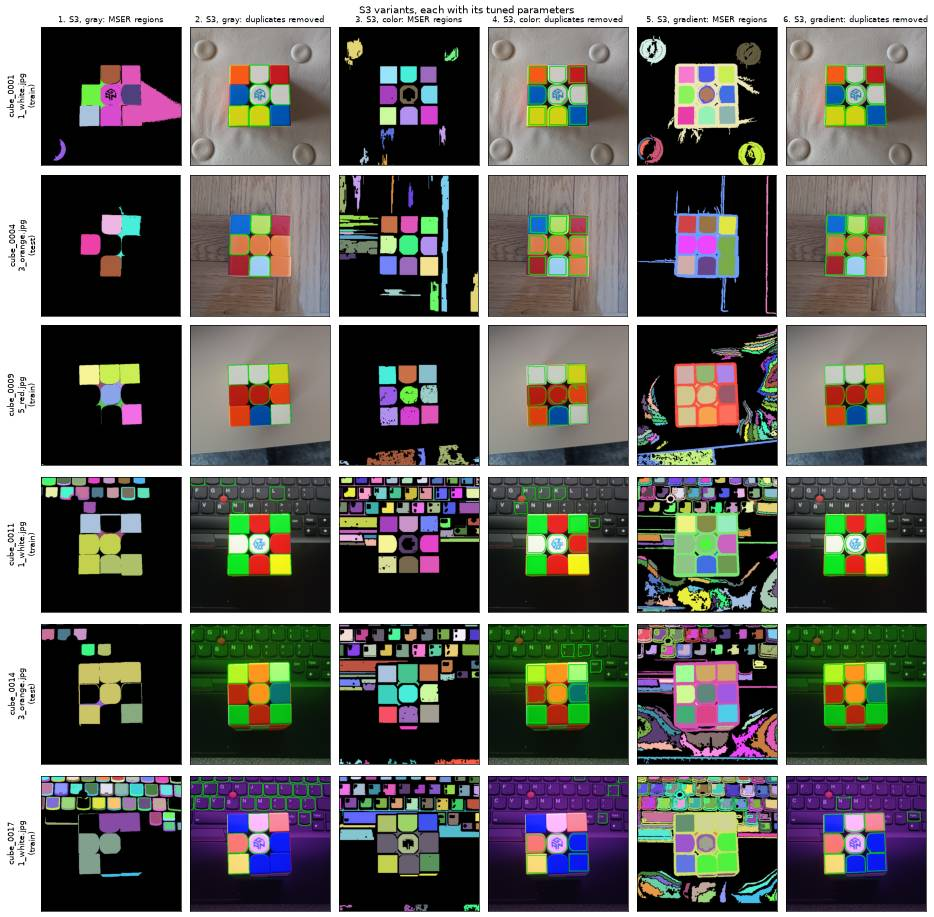

In [52]:
show_stages(
    stage_variants(list(S3_GRIDS), ["MSER regions", "duplicates removed"], run_cells),
    "S3 variants, each with its tuned parameters",
)

### G: 3 x 3 grid

Completes the stickers found by S1, S2 or S3 to 9 and drops the ones off the face. In a
frontal view the stickers lie on a square lattice.

**Input:** sticker contours of S1, S2 or S3 (tuned) · **Output:** 9 sticker polygons, or none

1. **Input** – contours of S1, S2 or S3
2. **Anchor, similar** – every cell is tried as the anchor; cells of similar area (ratio below
   `size_ratio`, or all cells if None) give the orientation (mean angle mod 90 of their
   rectangles) and the pitch (median distance to the nearest one). Shown: the winning anchor
   (magenta) and its similar cells (green)
3. **Lattice coordinates** – positions relative to the anchor divided by the pitch; cells
   within `tolerance` (fraction of the pitch) of integer coordinates inside a 3 x 3 window are
   inliers (green, labeled column, row), others red. The anchor and window with most inliers
   win; `tie` = area: equal counts are decided by the larger total area, first: the first found
   stays. At least `min_cells` inliers
4. **Grid** – a similarity fitted to the inliers places the missing cells (blue) as squares of
   the median size; found cells green

**Grid:** `size_ratio` – None, 95th and 99th percentile and 1.5 x the 99th of the sticker
area ratio within the annotated faces; `tie` – area, first; `tolerance` – 0.15, 0.25, 0.35;
`min_cells` – 3 (the least for a similarity with a check), 4, 5.

In [53]:
def lattice_fit(cells, p):
    """Best lattice: anchor, similar, inliers, grid coordinates, similarity; or None"""
    if len(cells) < p["min_cells"]:
        return None
    rects = [cv2.minAreaRect(np.int32(c).reshape(-1, 1, 2)) for c in cells]
    centers = np.array([r[0] for r in rects])
    areas = np.array([cv2.contourArea(np.int32(c)) for c in cells])
    angles = np.radians([r[2] for r in rects])
    best, best_score = None, (0, 0.0)
    for anchor in range(len(cells)):
        if p["size_ratio"] is None:
            similar = np.ones(len(cells), bool)
        else:
            similar = np.abs(np.log(areas / areas[anchor])) < np.log(p["size_ratio"])
        if similar.sum() < p["min_cells"]:
            continue
        angle = np.angle(np.mean(np.exp(4j * angles[similar]))) / 4
        rotation = np.array([[np.cos(angle), np.sin(angle)], [-np.sin(angle), np.cos(angle)]])
        local = centers @ rotation.T
        group = local[similar]
        distances = np.linalg.norm(group[:, None] - group[None], axis=2)
        np.fill_diagonal(distances, np.inf)
        coords = (local - local[anchor]) / np.median(distances.min(axis=1))
        near = similar & (np.linalg.norm(coords - coords.round(), axis=1) < p["tolerance"])
        grid = coords.round().astype(int)
        for offset in [(ox, oy) for ox in range(-2, 1) for oy in range(-2, 1)]:
            shifted = grid - offset
            inside = near & np.all((shifted >= 0) & (shifted <= 2), axis=1)
            tie = float(areas[inside].sum()) if p["tie"] == "area" else 0.0
            score = (int(inside.sum()), tie)
            if score > best_score:
                best = {"anchor": anchor, "similar": similar, "inliers": inside, "grid": shifted}
                best_score = score
    if best is None or best_score[0] < p["min_cells"]:
        return None
    inliers = best["inliers"]
    transform, _ = cv2.estimateAffinePartial2D(
        np.float32(best["grid"][inliers]), np.float32(centers[inliers])
    )
    if transform is None:
        return None
    return best | {"transform": transform, "centers": centers}


def to_photo(transform, points):
    return np.array(points, np.float32) @ transform[:, :2].T + transform[:, 2]


def label_inliers(photo, cells, fit):
    out = draw(photo, cells, REJECTED, 1)
    for i in np.flatnonzero(fit["inliers"]):
        col, row = fit["grid"][i]
        out = draw(out, [cells[i]], ACCEPTED)
        x, y = np.int32(fit["centers"][i])
        cv2.putText(out, f"{col},{row}", (int(x) - 14, int(y) + 5), 0, 0.5, (0, 0, 0), 2)
    return out


def g(photo, cells, p, st=NO_STAGES):
    """9 sticker polygons in reading order, or [] if no lattice fits"""
    st.add("input", lambda: draw(photo, cells))
    fit = lattice_fit(cells, p)
    if fit is None:
        return []
    similar = [c for c, s in zip(cells, fit["similar"], strict=True) if s]
    st.add(
        "anchor, similar",
        lambda: draw(draw(photo, similar, ACCEPTED), [cells[fit["anchor"]]], (255, 0, 255), 5),
    )
    st.add("lattice coordinates", lambda: label_inliers(photo, cells, fit))
    known = {tuple(fit["grid"][i]): cells[i] for i in np.flatnonzero(fit["inliers"])}
    transform = fit["transform"]
    half = np.median([np.sqrt(cv2.contourArea(np.int32(c))) for c in known.values()]) / 2
    square = (
        np.array([(-1, -1), (1, -1), (1, 1), (-1, 1)]) * half / np.linalg.norm(transform[:, 0])
    )
    added = {
        (col, row): to_photo(transform, np.add(square, (col, row)))
        for row in range(3)
        for col in range(3)
        if (col, row) not in known
    }
    st.add(
        "grid",
        lambda: draw(draw(photo, list(known.values()), ACCEPTED), list(added.values()), ADDED),
    )
    return [known.get((col, row), added.get((col, row))) for row in range(3) for col in range(3)]


G_ON = {  # G method -> S method under it
    "S1, fitted + G": "S1, fitted",
    "S2, gray + G": "S2, gray",
    "S2, Lab + G": "S2, Lab",
    "S3, gray + G": "S3, gray",
    "S3, color + G": "S3, color",
    "S3, gradient + G": "S3, gradient",
}


@functools.cache
def best_nine(name, image_key):
    return g(None, best_cells(G_ON[name], image_key), BEST[name])


def tune_g(name):
    def prepare(image, _):
        return best_cells(G_ON[name], key(image)), truth_polygons(image)

    def score(prepared, p):
        return np.mean([found_count(match(g(None, c, p), truth)) == 9 for c, truth in prepared])

    BEST[name] = tune(name, G_GRID, prepare, score)
    best_nine.cache_clear()


ratio = faces["sticker area max / min"]
G_GRID = {
    "size_ratio": [
        None,
        round(ratio.quantile(0.95), 2),
        round(ratio.quantile(0.99), 2),
        round(1.5 * ratio.quantile(0.99), 2),
    ],
    "tie": ["area", "first"],
    "tolerance": [0.15, 0.25, 0.35],
    "min_cells": [3, 4, 5],
}
for name in G_ON:
    tune_g(name)

S1, fitted + G: 100%|██████████| 1/1 [00:33<00:00, 33.41s/it]

S1, fitted + G: 72 combinations, best score 0.810


,size_ratio,tie,tolerance,min_cells,score
24,1.30,area,0.35,3,0.809524
33,1.30,first,0.35,3,0.809524
42,1.35,area,0.35,3,0.809524
51,1.35,first,0.35,3,0.809524
18,1.30,area,0.15,3,0.801587


S2, gray + G: 100%|██████████| 1/1 [00:25<00:00, 25.00s/it]

S2, gray + G: 72 combinations, best score 0.968


...

S3, color + G: 72 combinations, best score 0.873


,size_ratio,tie,tolerance,min_cells,score
21,1.30,area,0.25,3,0.873016
24,1.30,area,0.35,3,0.873016
30,1.30,first,0.25,3,0.873016
33,1.30,first,0.35,3,0.873016
39,1.35,area,0.25,3,0.873016


S3, gradient + G: 100%|██████████| 1/1 [01:02<00:00, 62.33s/it]

S3, gradient + G: 72 combinations, best score 0.984


,size_ratio,tie,tolerance,min_cells,score
18,1.3,area,0.15,3,0.984127
19,1.3,area,0.15,4,0.984127
20,1.3,area,0.15,5,0.984127
24,1.3,area,0.35,3,0.984127
25,1.3,area,0.35,4,0.984127


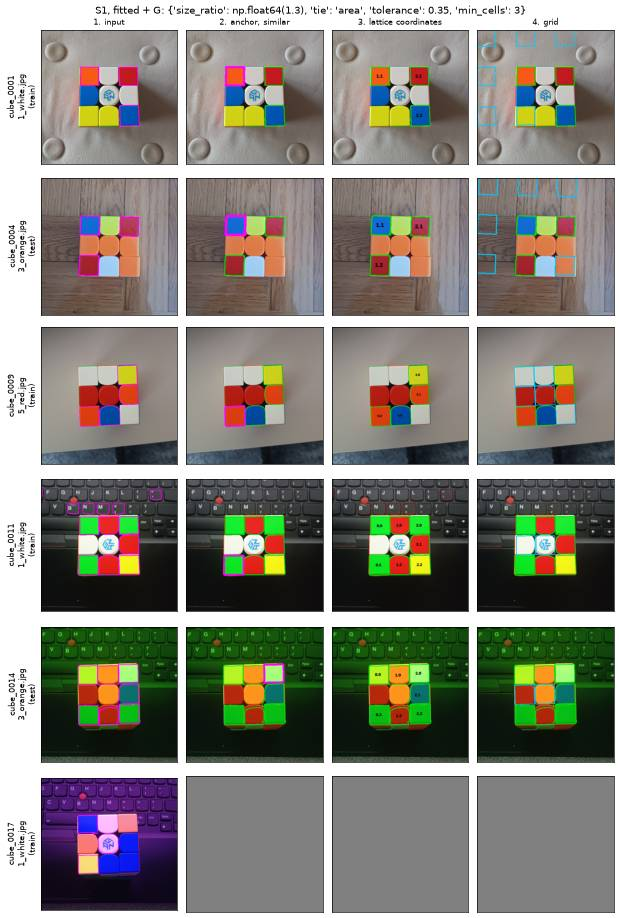

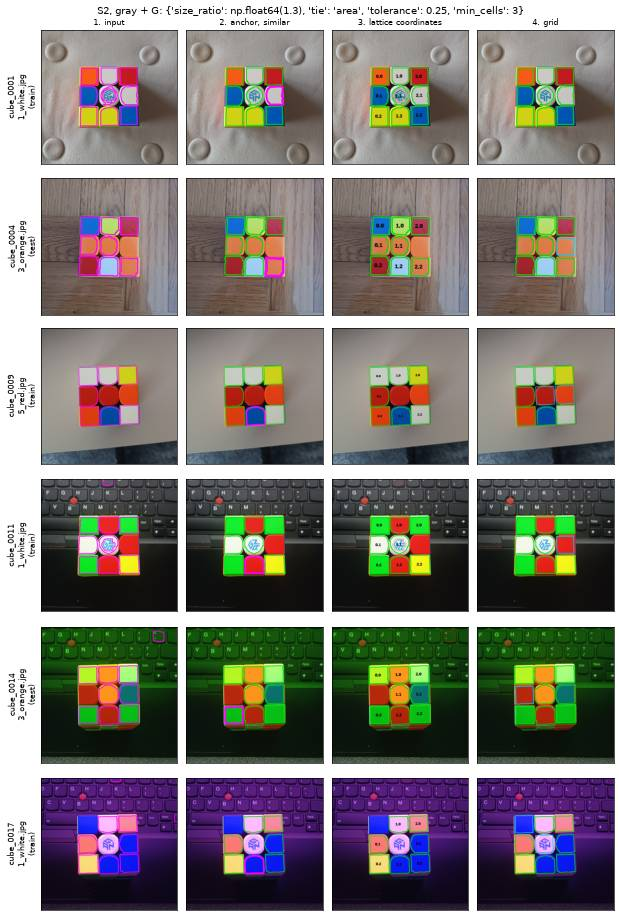

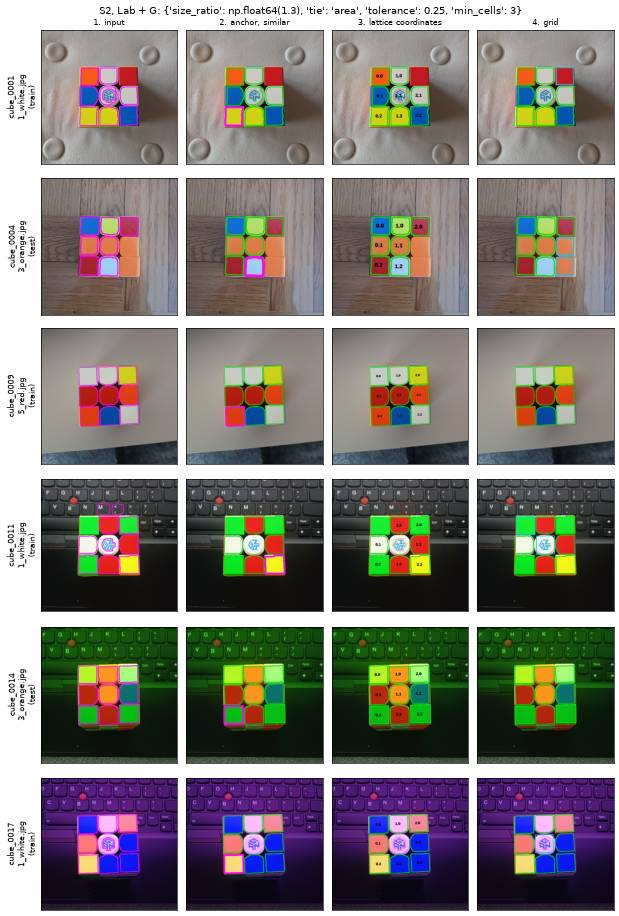

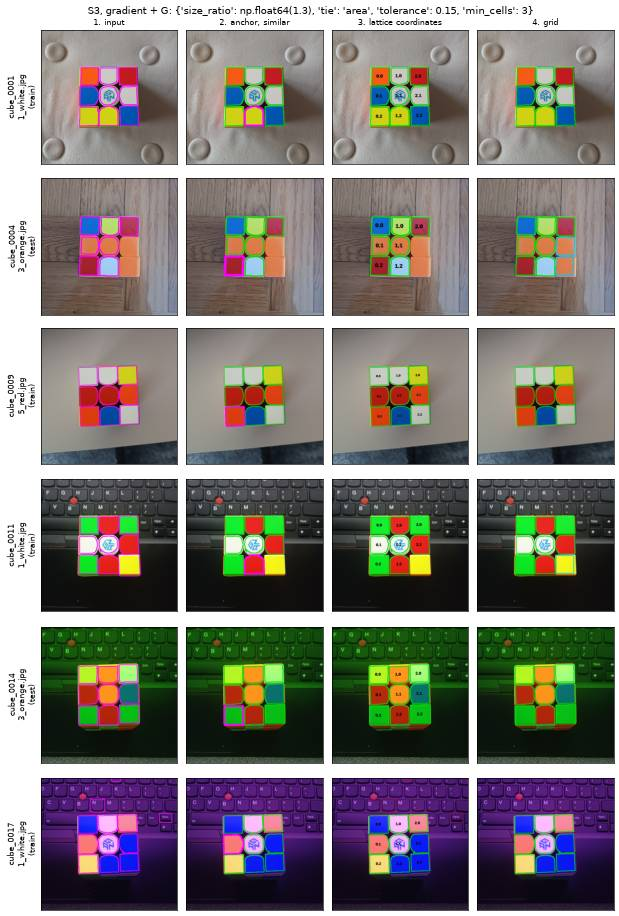

In [54]:
for name in ("S1, fitted + G", "S2, gray + G", "S2, Lab + G", "S3, gradient + G"):
    show_stages(
        lambda photo, _, st, name=name: g(photo, run_cells(G_ON[name], photo), BEST[name], st),
        f"{name}: {BEST[name]}",
    )

## Part B: whole face

A method F finds the face as a quadrilateral (`quadrilateral`: convex hull simplified to 4
vertices, see *Setup*); R, common to all of them, maps it to a square and cuts the 3 x 3 grid.

### F1: saturation

Stickers are saturated, typical backgrounds are not.

**Input:** photo · **Output:** quadrilateral

1. **Saturation** – S of HSV
2. **Otsu** – threshold between the two modes of the histogram
3. **Opening** – `opening` x `opening`, removes small spots
4. **Closing** – `closing` x `closing`, fills seams and low-saturation (white) stickers
   enclosed by others
5. **Component** – the connected component with the largest area / (1 + distance from the
   photo center)
6. **Quadrilateral** – convex hull (yellow) simplified to 4 vertices (magenta)

**Grid:** `opening` – odd sizes nearest to `SEAM` / 2, `SEAM` (1: none); `closing` – 1
(none) and odd sizes nearest to `SEAM` (seams only), `STICKER` / 2, `STICKER`, 1.5 `STICKER`
(whole white stickers).

In [55]:
def f1(photo, p, st=NO_STAGES):
    saturation = cv2.cvtColor(photo, cv2.COLOR_BGR2HSV)[..., 1]
    st.add("saturation", saturation)
    _, otsu = cv2.threshold(saturation, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    st.add("Otsu", otsu)
    opened = cv2.morphologyEx(otsu, cv2.MORPH_OPEN, np.ones((p["opening"],) * 2, np.uint8))
    st.add("opening", opened)
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, np.ones((p["closing"],) * 2, np.uint8))
    st.add("closing", closed)
    n, labels, stats, centroids = cv2.connectedComponentsWithStats(closed)
    if n < 2:
        return None
    distance = np.linalg.norm(centroids[1:] - middle_of(photo), axis=1)
    component = np.uint8(labels == 1 + (stats[1:, cv2.CC_STAT_AREA] / (1 + distance)).argmax())
    st.add("component", component * 255)
    contour = contour_of(component)
    quad = quadrilateral(contour)
    st.add(
        "quadrilateral",
        lambda: draw(draw(photo, [cv2.convexHull(contour)], (0, 255, 255)), [quad]),
    )
    return quad


FACES = {"F1": f1}


@functools.cache
def best_quad(name, image_key):
    return FACES[name](load(IMAGES[image_key]), BEST.get(name, {}))


def face_score(prepared, _):
    return np.mean([value >= FACE_IOU for value in prepared])


F1_GRID = {
    "opening": odds([SEAM / 2, SEAM]),
    "closing": odds([1, SEAM, STICKER / 2, STICKER, 1.5 * STICKER]),
}
BEST["F1"] = tune(
    "F1", F1_GRID, lambda image, p: face_iou(f1(load(image), p), image), face_score, list(F1_GRID)
)
best_quad.cache_clear()

F1: 100%|██████████| 10/10 [00:07<00:00,  1.31it/s]

F1: 10 combinations, best score 0.206


,opening,closing,score
2,1,37,0.206349
1,1,3,0.190476
3,1,75,0.190476
0,1,1,0.166667
4,1,113,0.150794


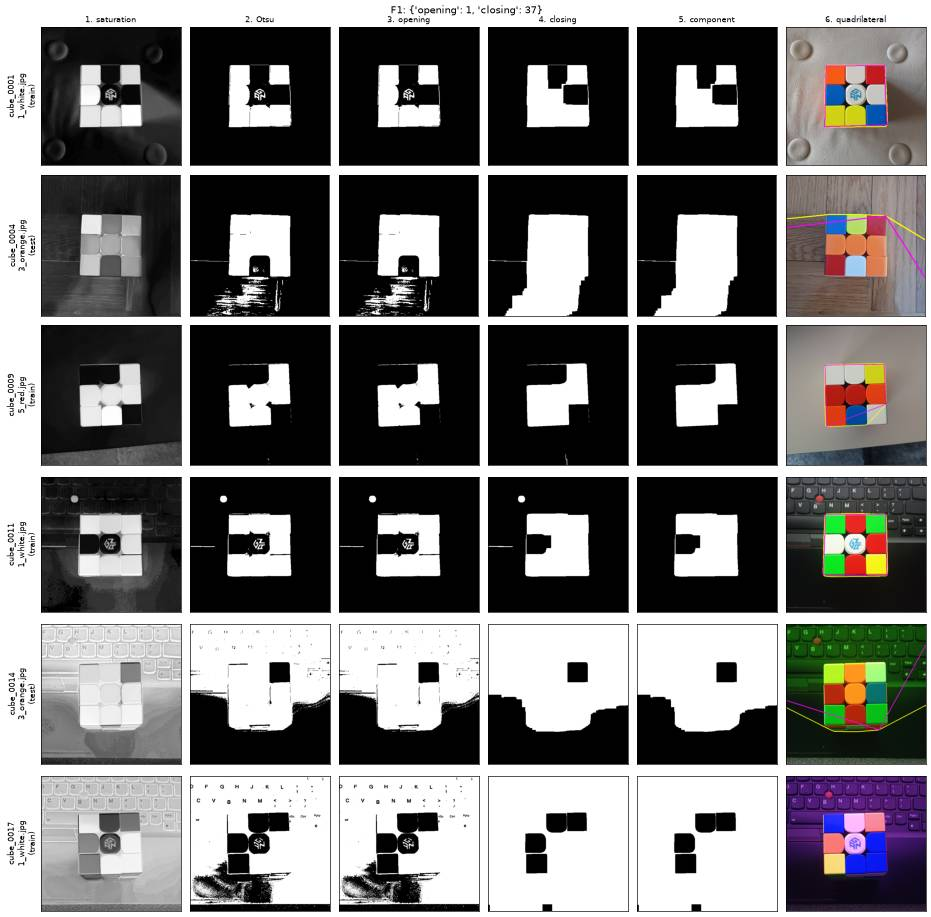

In [56]:
show_stages(lambda photo, _, st: f1(photo, BEST["F1"], st), f"F1: {BEST['F1']}")

### F2: outline of the Canny edges

The seams connect the edges of all stickers with the outline of the face into one structure;
its outer contour is the face.

**Input:** photo · **Output:** quadrilateral

1-4. **Edges** – stages 1-4 of S2 (gray or Lab variant), with F2's own parameters
5. **Outer contours** – of connected edge structures, each in its own color
6. **Candidates** – quadrilaterals of the contours above `FACE_MIN_AREA` of the photo;
   accepted (green) if the aspect of the quadrilateral is at most `side_ratio` and the contour
   fills it (quadrilateral area / contour area at most `fill`), else red
7. **Face** – the accepted candidate with the largest area / (1 + distance from the center)

**Variants:** gray and Lab, as S2.

**Grid:** the edge grid of the S2 variant; `side_ratio` – 95th and 99th percentile and 1.25,
1.5 x the 99th of the aspect of the annotated faces; `fill` – 1.1, 1.2, 1.3.

In [57]:
def outline_candidates(photo, p, st=NO_STAGES):
    edges = edge_map(photo, p, st)
    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    st.add("outer contours", lambda: draw_colored(photo.shape, contours))
    candidates = []
    for contour in contours:
        area = cv2.contourArea(contour)
        if area < FACE_MIN_AREA * photo.shape[0] * photo.shape[1]:
            continue
        quad = quadrilateral(contour)
        _, (w, h), _ = cv2.minAreaRect(quad)
        if min(w, h) == 0:
            continue
        candidates.append(
            {
                "quad": quad,
                "area": area,
                "ratio": max(w, h) / min(w, h),
                "fill": cv2.contourArea(quad) / area,
                "distance": np.linalg.norm(quad.mean(axis=0) - middle_of(photo)),
            }
        )
    return candidates


def draw_colored(shape, contours):
    out = np.zeros((*shape[:2], 3), np.uint8)
    colors = random_colors(np.arange(len(contours) + 1))[1:]
    for contour, color in zip(contours, colors, strict=True):
        cv2.drawContours(out, [contour], -1, color.tolist(), 2)
    return out


def choose_outline(candidates, p):
    accepted = [c for c in candidates if c["ratio"] <= p["side_ratio"] and c["fill"] <= p["fill"]]
    if not accepted:
        return None, accepted
    return max(accepted, key=lambda c: c["area"] / (1 + c["distance"])), accepted


def f2(photo, p, st=NO_STAGES):
    candidates = outline_candidates(photo, p, st)
    best, accepted = choose_outline(candidates, p)
    ids = {id(c) for c in accepted}
    st.add(
        "candidates",
        lambda: draw_decisions(
            photo,
            [c["quad"] for c in accepted],
            [c["quad"] for c in candidates if id(c) not in ids],
        ),
    )
    if best is None:
        return None
    st.add("face", lambda: draw(photo, [best["quad"]]))
    return best["quad"]


def tune_f2(name, source):
    def prepare(image, up):
        candidates = outline_candidates(load(image), {"source": source} | up)
        return [c | {"iou": face_iou(c["quad"], image)} for c in candidates]

    def score(prepared, p):
        return np.mean([(c := choose_outline(cs, p)[0]) is not None and c["iou"] >= FACE_IOU
                        for cs in prepared])  # fmt: skip

    face_99 = faces.aspect.quantile(0.99)
    grid = EDGE_GRIDS[source] | {
        "side_ratio": sorted(
            {round(faces.aspect.quantile(0.95), 2), round(face_99, 2)}
            | {round(f * face_99, 2) for f in (1.25, 1.5)}
        ),
        "fill": [1.1, 1.2, 1.3],
    }
    BEST[name] = {"source": source} | tune(name, grid, prepare, score, list(EDGE_GRIDS[source]))
    best_quad.cache_clear()


for source in EDGE_GRIDS:
    FACES[f"F2, {source}"] = f2
    tune_f2(f"F2, {source}", source)

F2, gray: 100%|██████████| 60/60 [00:41<00:00,  1.44it/s]

F2, gray: 720 combinations, best score 0.437


,blur,canny_low,canny_ratio,dilation,side_ratio,fill,score
428,3,60,3,5,1.33,1.3,0.436508
431,3,60,3,5,1.60,1.3,0.436508
620,7,40,3,5,1.33,1.3,0.420635
623,7,40,3,5,1.60,1.3,0.420635
427,3,60,3,5,1.33,1.2,0.404762


F2, Lab: 100%|██████████| 60/60 [01:36<00:00,  1.61s/it]

F2, Lab: 720 combinations, best score 0.437


,sigma,canny_low,canny_ratio,dilation,side_ratio,fill,score
115,1.93,40,2,5,1.33,1.2,0.436508
116,1.93,40,2,5,1.33,1.3,0.436508
118,1.93,40,2,5,1.60,1.2,0.436508
119,1.93,40,2,5,1.60,1.3,0.436508
114,1.93,40,2,5,1.33,1.1,0.420635


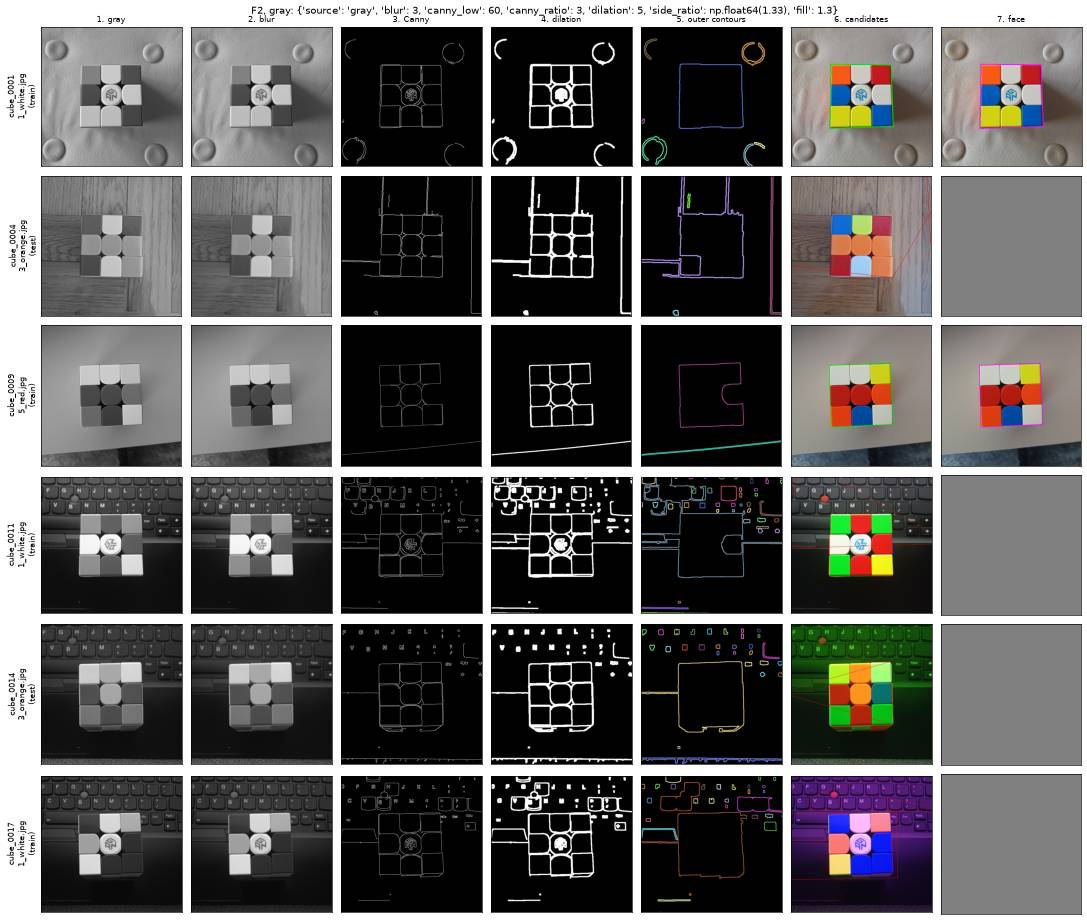

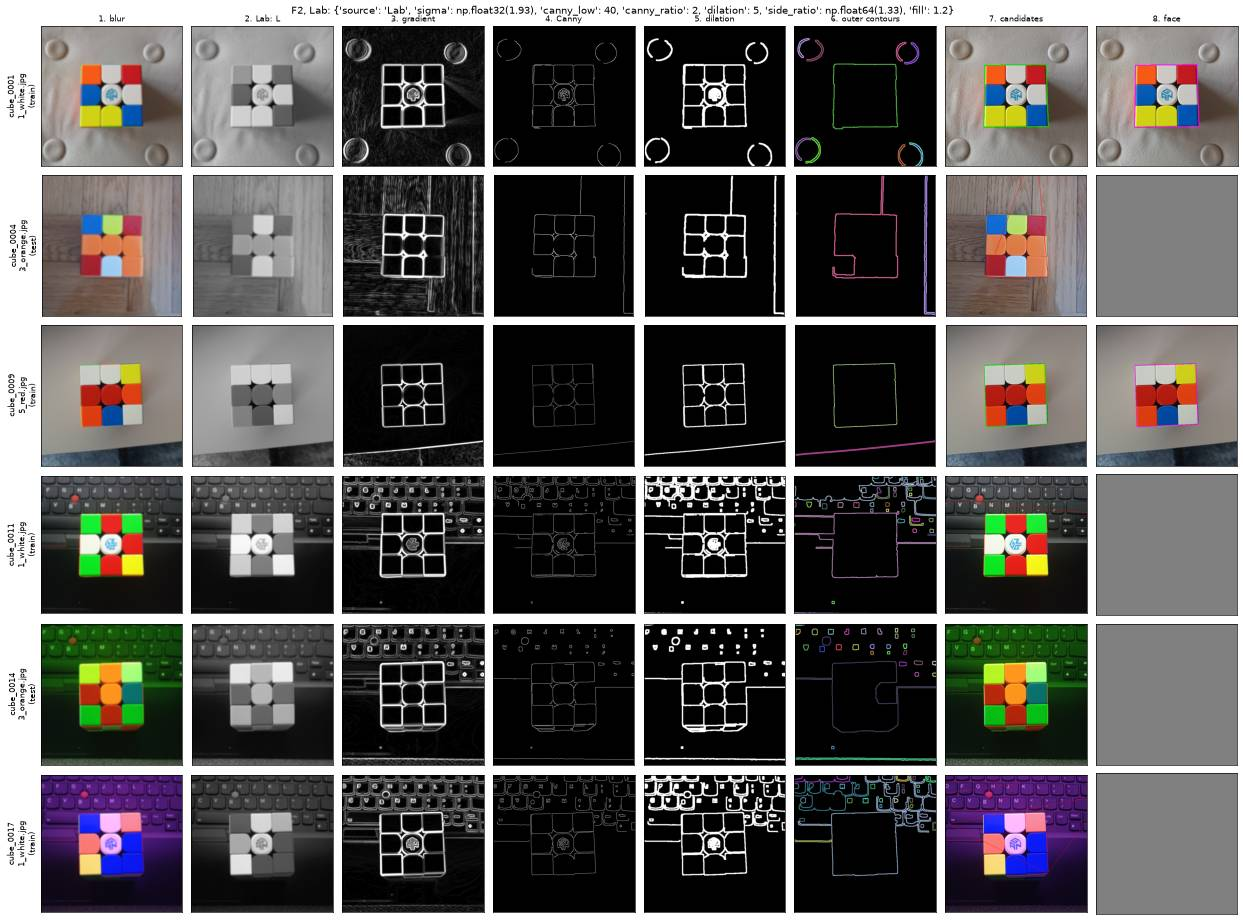

In [58]:
for source in EDGE_GRIDS:
    name = f"F2, {source}"
    show_stages(lambda photo, _, st, name=name: f2(photo, BEST[name], st), f"{name}: {BEST[name]}")

### F3: face from the stickers

Bottom-up: the grid of S2 + G already says where the face is. No parameters of its own: the
S2 variant whose G scored better on the training photos, S2 and G as tuned.

**Input:** photo (runs S2, then G) · **Output:** quadrilateral

1. **S2 + G** – the 9 stickers (stage 4 of G)
2. **Grid corners** – the similarity of G applied to the outer corners of the grid, half a
   pitch beyond the corner cells: (-0.5, -0.5), (2.5, -0.5), (2.5, 2.5), (-0.5, 2.5)
3. **Face** – the quadrilateral through them

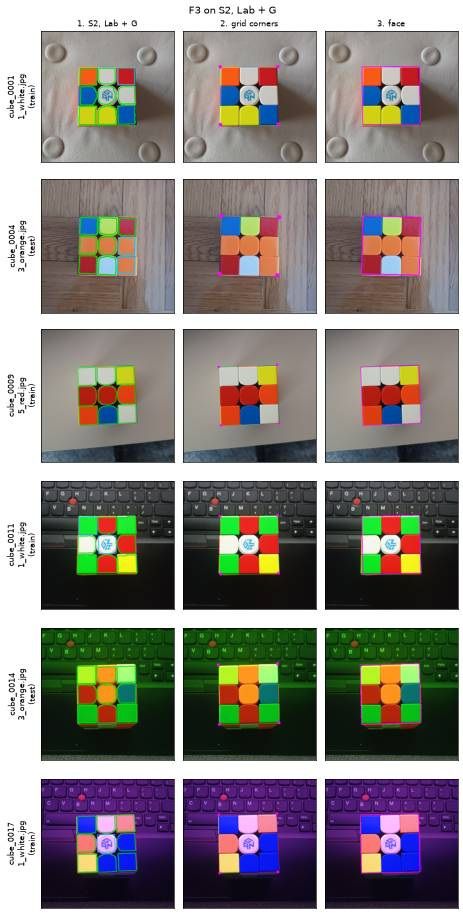

In [59]:
GRID_CORNERS = [(-0.5, -0.5), (2.5, -0.5), (2.5, 2.5), (-0.5, 2.5)]


def f3(photo, _, st=NO_STAGES):
    cells_ = run_cells(G_ON[F3_GRID_OF], photo)
    sub = Stages(show=st.show)
    g(photo, cells_, BEST[F3_GRID_OF], sub)
    st.add(F3_GRID_OF, sub.get("grid", photo))
    fit = lattice_fit(cells_, BEST[F3_GRID_OF])
    if fit is None:
        return None
    quad = order_corners(to_photo(fit["transform"], GRID_CORNERS))

    def corners():
        out = photo.copy()
        for x, y in np.int32(quad):
            cv2.circle(out, (int(x), int(y)), 6, (255, 0, 255), -1)
        return out

    st.add("grid corners", corners)
    st.add("face", lambda: draw(photo, [quad]))
    return quad


F3_GRID_OF = max(("S2, gray + G", "S2, Lab + G"), key=SCORES.get)
FACES["F3"] = f3
show_stages(lambda photo, _, st: f3(photo, None, st), f"F3 on {F3_GRID_OF}")

### R: rectified face, 9 stickers and the seam check

Common ending of every F, tuned separately after each. A homography is exact for a plane,
so the 3 x 3 grid of the rectified face is right whenever the quadrilateral is the face. The
check tests that: the seams must be at 1/3 and 2/3 of each side.

**Input:** quadrilateral · **Output:** 9 sticker polygons, check passed or not

1. **Quadrilateral** – of F1, F2 or F3
2. **Rectified** – homography to a `GRID_SIZE` square
3. **Black-hat** – closing minus the image, `black_hat` kernel: keeps dark lines thinner than
   the kernel (seams); contrast stretched for display
4. **Seam profiles** – mean of the black-hat over rows (x, blue) and over columns (y, orange).
   The check passes if in both directions the strongest peak within 1/3 +- 1/6 and 2/3 +- 1/6
   (half the distance to the next seam or the border) is at most `tolerance` from its place
   and at least `contrast` x the median of the profile
5. **Stickers** – the 9 cells of the square, inset by `inset` of a cell, mapped back to the
   photo; green if the check passed, red if not

**Grid:** `black_hat` – odd sizes nearest to 1.5, 2 and 3 `SEAM_RECT` (above the seam
width); `tolerance` – 95th and 99th percentile and 2 x the 99th of the seam offsets of the
annotated faces; `contrast` – 1.5, 2, 3, 4, 6; `inset` – 0, 0.1, 0.2.

In [60]:
def seam_profiles(face, black_hat, st=NO_STAGES):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (black_hat, black_hat))
    hat = cv2.morphologyEx(cv2.cvtColor(face, cv2.COLOR_BGR2GRAY), cv2.MORPH_BLACKHAT, kernel)
    st.add("black-hat", lambda: cv2.normalize(hat, None, 0, 255, cv2.NORM_MINMAX))
    return hat.mean(axis=0), hat.mean(axis=1)


def seams_ok(profiles, tolerance, contrast):
    for profile in profiles:
        level = np.median(profile)
        for expected in (1 / 3, 2 / 3):
            lo, hi = int((expected - 1 / 6) * GRID_SIZE), int((expected + 1 / 6) * GRID_SIZE)
            peak = lo + int(profile[lo:hi].argmax())
            if abs(peak / GRID_SIZE - expected) > tolerance:
                return False
            if profile[peak] < contrast * level:
                return False
    return True


def grid_cells(homography, inset):
    cell, inverse = GRID_SIZE / 3, np.linalg.inv(homography)
    nine = []
    for row in range(3):
        for col in range(3):
            x0, y0 = (col + inset) * cell, (row + inset) * cell
            x1, y1 = (col + 1 - inset) * cell, (row + 1 - inset) * cell
            square = np.float32([(x0, y0), (x1, y0), (x1, y1), (x0, y1)])[:, None]
            nine.append(cv2.perspectiveTransform(square, inverse)[:, 0])
    return nine


def r(photo, quad, p, st=NO_STAGES):
    """9 stickers and whether the seam check passed"""
    st.add("quadrilateral", lambda: photo if quad is None else draw(photo, [quad]))
    if quad is None:
        return [], False
    face, homography = rectify(photo, quad)
    st.add("rectified", face)
    profiles = seam_profiles(face, p["black_hat"], st)
    ok = seams_ok(profiles, p["tolerance"], p["contrast"])
    color = ACCEPTED if ok else REJECTED
    st.add(
        "seam profiles", lambda: profile_panel(profiles, "ok" if ok else "fail", text_color=color)
    )
    nine = grid_cells(homography, p["inset"])
    st.add("stickers", lambda: draw(photo, nine, color))
    return nine, ok


offsets = seams["seam offset"].abs()
R_GRID = {
    "black_hat": odds([1.5 * SEAM_RECT, 2 * SEAM_RECT, 3 * SEAM_RECT]),
    "inset": [0, 0.1, 0.2],
    "tolerance": [
        round(offsets.quantile(0.95), 3),
        round(offsets.quantile(0.99), 3),
        round(2 * offsets.quantile(0.99), 3),
    ],
    "contrast": [1.5, 2, 3, 4, 6],
}


def tune_r(f_name):
    def prepare(image, up):
        quad = best_quad(f_name, key(image))
        if quad is None:
            return None
        face, homography = rectify(load(image), quad)
        nine = grid_cells(homography, up["inset"])
        all_found = found_count(match(nine, truth_polygons(image))) == 9
        return seam_profiles(face, up["black_hat"]), all_found

    def score(prepared, p):
        net = 0
        for item in prepared:
            if item is not None and seams_ok(item[0], p["tolerance"], p["contrast"]):
                net += 1 if item[1] else -1
        return net / len(prepared)

    BEST[f"R after {f_name}"] = tune(
        f"R after {f_name}", R_GRID, prepare, score, ["black_hat", "inset"]
    )


for f_name in FACES:
    tune_r(f_name)

R after F1: 100%|██████████| 9/9 [00:04<00:00,  2.08it/s]

R after F1: 135 combinations, best score 0.214


,black_hat,inset,tolerance,contrast,score
10,9,0.0,0.04,1.5,0.214286
11,9,0.0,0.04,2.0,0.214286
12,9,0.0,0.04,3.0,0.214286
13,9,0.0,0.04,4.0,0.214286
25,9,0.1,0.04,1.5,0.214286


R after F2, gray: 100%|██████████| 9/9 [00:02<00:00,  3.54it/s]

R after F2, gray: 135 combinations, best score 0.397


...

R after F2, Lab: 135 combinations, best score 0.405


,black_hat,inset,tolerance,contrast,score
10,9,0.0,0.04,1.5,0.404762
11,9,0.0,0.04,2.0,0.404762
12,9,0.0,0.04,3.0,0.404762
25,9,0.1,0.04,1.5,0.404762
26,9,0.1,0.04,2.0,0.404762


R after F3: 100%|██████████| 9/9 [00:04<00:00,  1.92it/s]

R after F3: 135 combinations, best score 0.960


,black_hat,inset,tolerance,contrast,score
100,17,0.0,0.04,1.5,0.960317
101,17,0.0,0.04,2.0,0.952381
116,17,0.1,0.04,2.0,0.952381
115,17,0.1,0.04,1.5,0.944444
55,13,0.0,0.04,1.5,0.936508


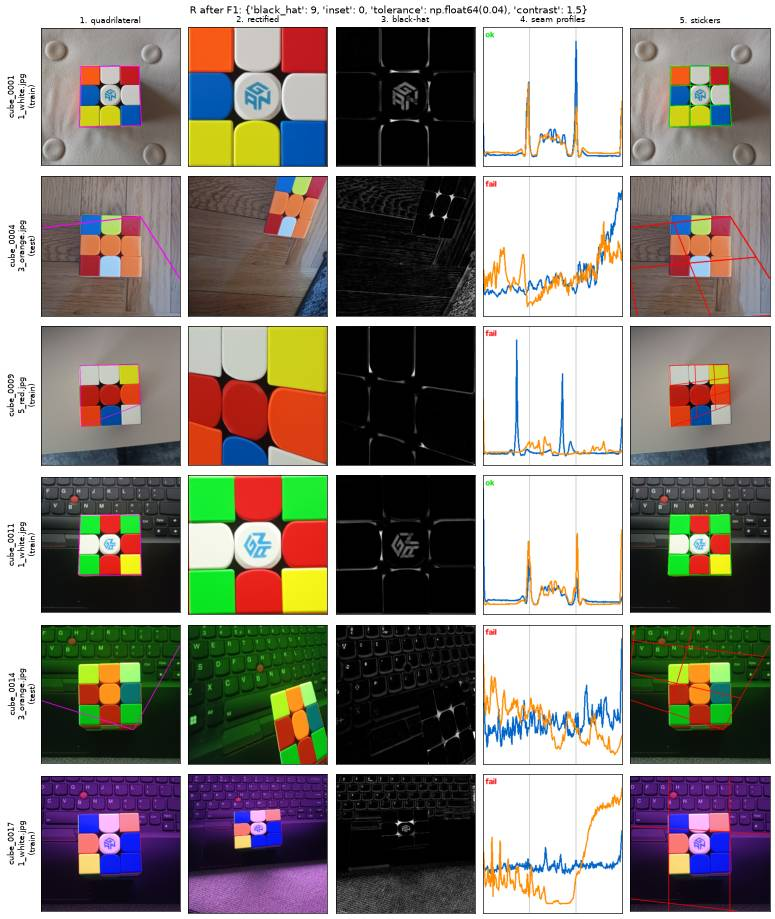

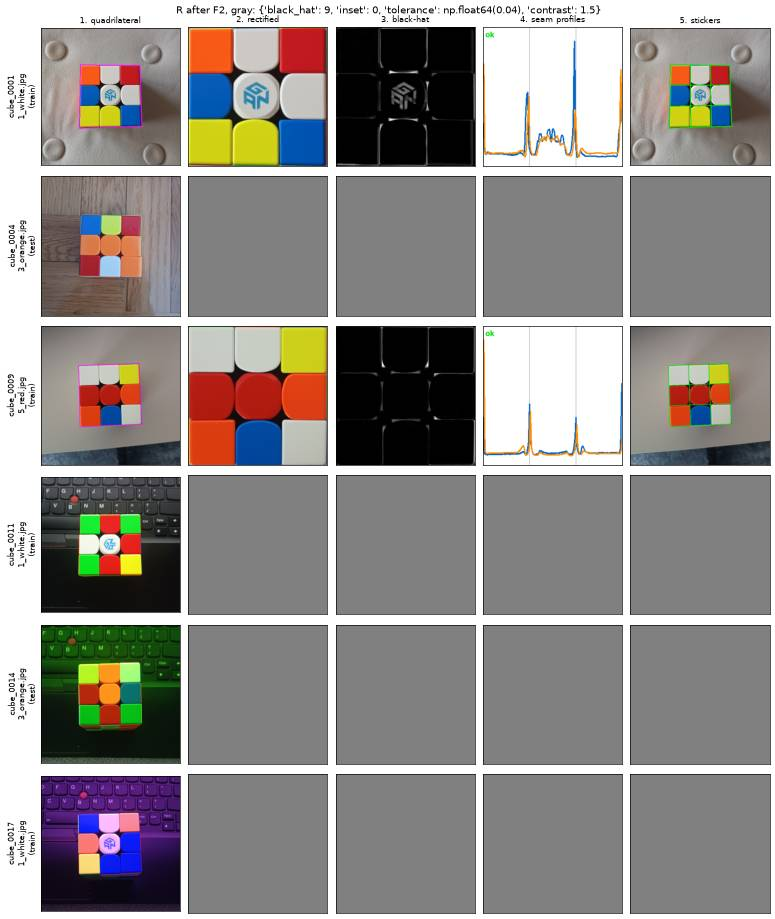

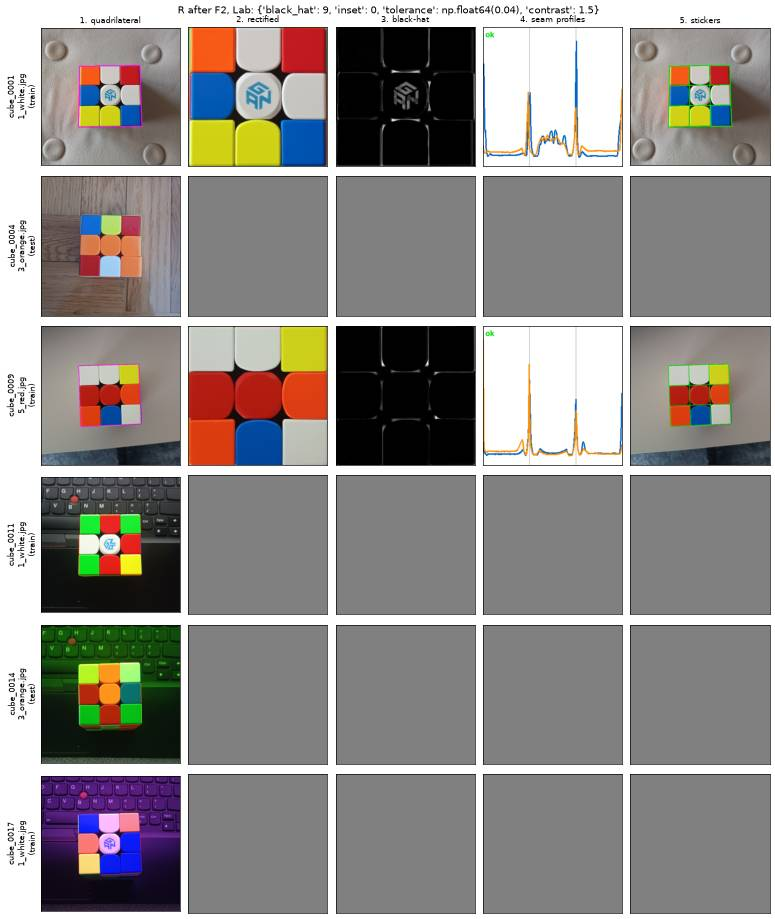

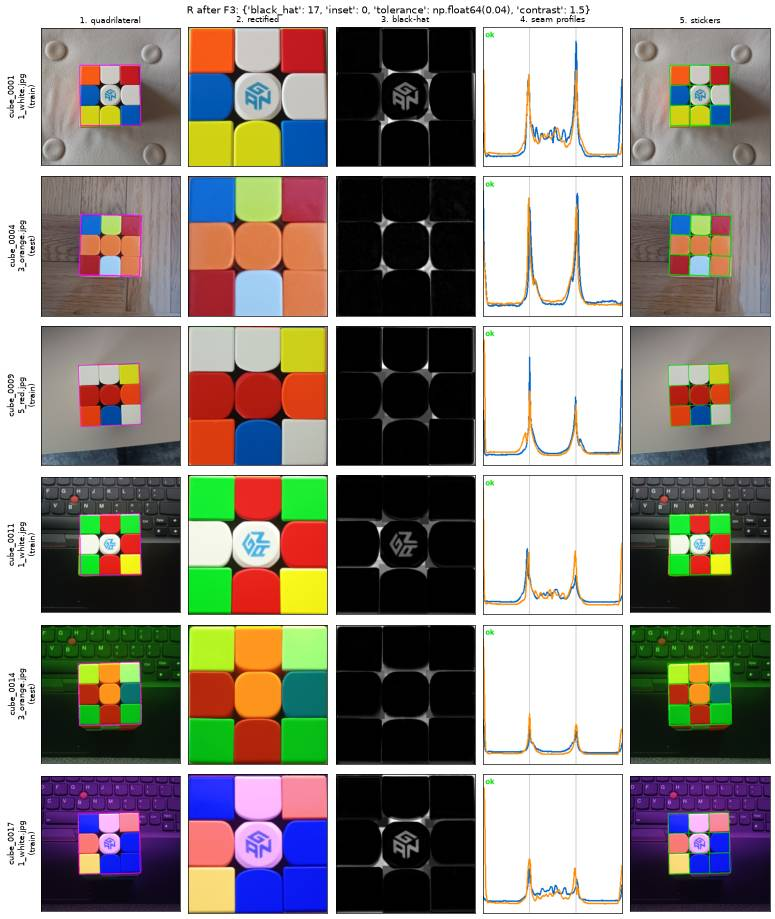

In [61]:
for f_name, find_face in FACES.items():
    name = f"R after {f_name}"
    show_stages(
        lambda photo, _, st, f_name=f_name, find_face=find_face, name=name: r(
            photo, find_face(photo, BEST.get(f_name, {})), BEST[name], st
        ),
        f"{name}: {BEST[name]}",
    )

## Summary

Every method with its tuned parameters on the training and the test photos.

- **F1, recall, precision** – of stickers, as in tuning (recall = found / 9, precision =
  found / returned regions)
- **photos with 9 / 9** – all annotated stickers matched
- **face IoU >= 0.9** – of the quadrilateral of F
- **check passed** – by R; **accepted, 9 / 9** – passed with all 9 found; **false accept** –
  passed without; **false reject** – failed with all 9 found
- **time, ms** – mean time of the method per photo, the photo already loaded and downscaled
  to `WIDTH`; methods built on others include them (G its S, F3 S2 and G, F + R both); on
  the CPU printed below, OpenCV with its default threads

In [62]:
def timed(run, *args):
    start = time.perf_counter()
    result = run(*args)
    return result, 1000 * (time.perf_counter() - start)


def face_and_r(photo, f_name):
    quad = FACES[f_name](photo, BEST.get(f_name, {}))
    return quad, *r(photo, quad, BEST[f"R after {f_name}"])


def evaluate(subset):
    """Every method run anew per photo (not from the tuning caches), to time it"""
    rows = []
    for image in tqdm(SETS[subset], desc=subset):
        photo, truth = load(image), truth_polygons(image)
        cells_of, ms_of = {}, {}
        for name in S_METHODS:
            cells_of[name], ms_of[name] = timed(run_cells, name, photo)
            rows.append({"method": name, "found": found_count(match(cells_of[name], truth))})
            rows[-1] |= {"regions": len(cells_of[name]), "time, ms": ms_of[name]}
        for name, s_name in G_ON.items():
            nine, ms = timed(g, None, cells_of[s_name], BEST[name])
            rows.append({"method": name, "found": found_count(match(nine, truth))})
            rows[-1] |= {"regions": len(nine), "time, ms": ms_of[s_name] + ms}
        for f_name in FACES:
            (quad, nine, ok), ms = timed(face_and_r, photo, f_name)
            rows.append({"method": f"{f_name} + R", "found": found_count(match(nine, truth))})
            rows[-1] |= {"regions": len(nine), "time, ms": ms, "face IoU": face_iou(quad, image)}
            rows[-1]["check"] = ok
    return pd.DataFrame(rows).assign(split=subset)


def summarize(df):
    found, regions = df.found.sum(), df.regions.sum()
    precision = found / regions if regions else 0.0
    recall = found / (9 * len(df))
    out = {
        "F1": 2 * precision * recall / (precision + recall) if found else 0.0,
        "recall": recall,
        "precision": precision,
        "photos with 9 / 9": (df.found == 9).mean(),
        "time, ms": df["time, ms"].mean(),
    }
    if df["check"].notna().all():
        all_found, passed = df.found == 9, df["check"].astype(bool)
        out |= {
            "face IoU >= 0.9": (df["face IoU"] >= FACE_IOU).mean(),
            "check passed": passed.mean(),
            "accepted, 9 / 9": (passed & all_found).mean(),
            "false accept": (passed & ~all_found).mean(),
            "false reject": (~passed & all_found).mean(),
        }
    return pd.Series(out)


print(f"CPU: {platform.processor() or platform.machine()}, OpenCV threads: {cv2.getNumThreads()}")
results = pd.concat([evaluate("train"), evaluate("test")])

CPU: x86_64, OpenCV threads: 12


test: 100%|██████████| 84/84 [01:26<00:00,  1.03s/it]


In [63]:
# METRICS = [
#     *("F1", "recall", "precision", "photos with 9 / 9", "face IoU >= 0.9", "check passed"),
#     *("accepted, 9 / 9", "false accept", "false reject", "time, ms"),
# ]
METRICS = [
    *("F1", "recall", "precision", "time, ms"),
]
groups = results.groupby(["method", "split"], sort=False)
summary = pd.DataFrame({group: summarize(df) for group, df in groups}).T
summary = summary.rename_axis(["method", "split"]).reindex(columns=METRICS).unstack("split")
summary.reindex(results.method.unique()).reindex(columns=list(SETS), level="split").round(2)

F1       recall       precision       time, ms        
split            train  test  train  test     train  test    train    test
method                                                                    
S1, Table 1       0.62  0.63   0.45  0.47      0.99  0.98    60.05   62.52
S1, gray world    0.61  0.64   0.44  0.48      0.99  0.97    77.14   79.63
S1, fitted        0.74  0.66   0.64  0.55      0.88  0.81    63.25   63.99
S2, gray          0.93  0.90   0.93  0.88      0.93  0.92     4.33    4.53
S2, Lab           0.88  0.87   0.87  0.84      0.90  0.90     7.65    7.74
S3, gray          0.71  0.66   0.63  0.56      0.81  0.82    88.22   82.66
S3, color         0.78  0.79   0.72  0.73      0.86  0.86   280.89  284.76
S3, gradient      0.96  0.92   0.98  0.96      0.94  0.88   289.59  281.76
S1, fitted + G    0.91  0.81   0.87  0.74      0.95  0.89    64.61   65.29
S2, gray + G      0.99  0.96   0.98  0.94      0.99  0.98     5.88    6.08
S2, Lab + G       0.99  0.97   0.99  0.97      0.99  0.98     9.13    9.27
S3, gray + G      0.90  0.77   0.85  0.69      0.95  0.87    89.49   83.97
S3, color + G     0.95  0.92   0.93  0.88      0.97  0.97   282.19  286.04
S3, gradient + G  1.00  1.00   1.00  1.00      1.00  1.00   291.11  283.43
F1 + R            0.28  0.26   0.28  0.26      0.28  0.26     6.29    6.56
F2, gray + R      0.61  0.47   0.49  0.37      0.81  0.66     3.47    3.50
F2, Lab + R       0.63  0.58   0.53  0.49      0.78  0.72     7.28    7.45
F3 + R            0.99  0.97   0.99  0.96      0.99  0.97    12.08   12.24

In [64]:
pd.DataFrame(BEST).T

,opening,rect_ratio,m3_fraction,gamma_max,blur,canny_low,canny_ratio,dilation,sigma,delta,...,tie,tolerance,min_cells,closing,source,side_ratio,fill,black_hat,inset,contrast
"S1, Table 1",3.0,1.4,0.25,0.5,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"S1, gray world",3.0,1.4,0.25,0.5,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"S1, fitted",3.0,1.4,0.1,0.5,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"S2, gray",NaN,1.4,0.1,0.2,3.0,40.0,2.0,5.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"S2, Lab",NaN,1.4,0.1,0.2,NaN,20.0,3.0,5.0,1.93,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"S3, gray",NaN,1.12,0.05,0.5,NaN,NaN,NaN,NaN,NaN,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"S3, color",NaN,1.12,0.1,0.5,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"S3, gradient",NaN,1.4,0.05,0.2,NaN,NaN,NaN,NaN,1.93,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"S1, fitted + G",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,area,0.35,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"S2, gray + G",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,area,0.25,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
